## <span style="color:ORANGE"><b>TOPIC:- NLP Project for Disaster Tweet Classification!</b></span>

Disaster Tweet Classification is a Natural Language Processing (NLP) task that involves building machine learning models to automatically analyze text from Twitter (now X) and determine whether a specific tweet reports a real-world emergency (like an earthquake, wildfire, or terrorist attack) or uses disaster-related words metaphorically (such as saying "that test was an absolute trainwreck" or "this song is fire").
It is a classic binary text classification problem. The input is raw, unstructured text, and the output is a label: 1 (Real Disaster) or 0 (Not a Real Disaster).

## <span style="color:pink"><b>Why it is Important?</b></span>

Twitter has become a primary channel for real-time communication. During crises, people naturally turn to the platform to announce emergencies, seek help, or share eyewitness updates. However, the sheer volume of noise makes manual monitoring impossible.

 Here is why automating this process with NLP is critical:
*  Real-Time Disaster Response: Relief organizations, police, and firefighters can use classified tweets to monitor unfolding crises on the ground. By filtering out the noise, emergency services can deploy aid faster to exact locations.
*  Early Warning Systems: Machine learning models can detect sudden spikes in "Real Disaster" tweets in a specific geographic area, acting as an automated early alert system for earthquakes, flash floods, or industrial accidents before official reports are filed.
*  Filtering Social Media Noise: Human language is full of metaphors. A phrase like "The sky is bleeding" could be a poetic description of a sunset, or a report of a massive chemical fire. NLP models help separate casual, metaphorical banter from life-threatening emergencies.
*  Public Safety and Resource Allocation: Governments and humanitarian agencies (like the Red Cross or FEMA) can map real-time data to allocate medical supplies, rescue teams, and food to the hardest-hit areas.

## <span style="color:pink"><b>How the Technical Framework Works?</b></span>
A standard NLP project for this task typically follows this pipeline:

[ Raw Tweets ] ➔ [ Text Preprocessing ] ➔ [ Vectorization ] ➔ [ ML/DL Model ] ➔ [ Prediction: 0 or 1 ]
1. Data Preprocessing: Cleaning the tweets by removing URLs, HTML tags, emojis, punctuation, and stop words. Words are often reduced to their root forms (stemming/lemmatization).
2. Feature Extraction (Vectorization): Converting the cleaned text into numbers that a machine can understand.
	• Traditional methods: TF-IDF or Bag-of-Words.
	• Modern methods: Word embeddings (Word2Vec, GloVe) or Transformer tokens.
3. Model Training: Training a classifier on labeled data (such as the famous Kaggle "Natural Language Processing with Disaster Tweets" dataset).
	• Baseline models: Logistic Regression, Naive Bayes, or Support Vector Machines (SVM).
	• Advanced models: Deep learning networks like LSTMs or pre-trained Transformers like BERT and RoBERTa, which excel at understanding the context of words.


 ## <span style="color:green"><b>Part 1: Data Exploration and Preparation</b></span>

 ## <span style="color:LIGHTpink"><b>What is Library?</b></span>
 A library is a reusable collection of pre-written code, scripts, classes, or configuration files that software developers import into their own projects to perform specific tasks. Instead of writing everything from scratch, developers use libraries to save time, reduce errors, and add complex features effortlessly. I have used the following libraries.

In [108]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    roc_auc_score,
    precision_recall_curve,
    average_precision_score
)

print("Libraries imported successfully!")

Libraries imported successfully!


## <span style="color:LIGHTpink"><b>DataSets</b></span>
A dataset is a structured collection of related data, typically organized in tables, arrays, or files (like CSV or JSON). They are used for analysis, reporting, and training machine learning models. Datasets can range from simple spreadsheets to massive collections of images and text.

In [5]:
import os

print("Current notebook folder:")
print(os.getcwd())

print("\nFiles in this folder:")
for file in os.listdir():
    print(file)

Current notebook folder:
c:\Users\hp\Desktop\PROJECT 7

Files in this folder:
NLP PROJECT.ipynb
Project 7.pdf
Project_7_Disaster_Tweet_NLP.zip
twitter_disaster .csv


In [6]:
import os

for root, dirs, files in os.walk("."):
    for file in files:
        if file.lower().endswith(".csv"):
            print(os.path.join(root, file))

.\twitter_disaster .csv


In [7]:
import os

print("📁 Current folder:")
print(os.getcwd())

print("\n📄 CSV files found:")
for file in os.listdir():
    if file.lower().endswith(".csv"):
        print(repr(file))

📁 Current folder:
c:\Users\hp\Desktop\PROJECT 7

📄 CSV files found:
'twitter_disaster .csv'


In [8]:
import pandas as pd

df = pd.read_csv("twitter_disaster .csv", encoding="latin1")

print("✅ Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

display(df.head())

✅ Dataset loaded successfully!
Dataset Shape: (7613, 5)


,id,keyword,location,text,target
0,1,NaN,NaN,Our Deeds are the Reason of this #earthquake M...,1
1,4,NaN,NaN,Forest fire near La Ronge Sask. Canada,1
2,5,NaN,NaN,All residents asked to 'shelter in place' are ...,1
3,6,NaN,NaN,"13,000 people receive #wildfires evacuation or...",1
4,7,NaN,NaN,Just got sent this photo from Ruby #Alaska as ...,1


## <span style="color:LIGHTpink"><b> Task 1: Data Exploration</b></span>


In [9]:
print("========== DATASET INFORMATION ==========")

print("\nShape:")
print(df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

========== DATASET INFORMATION ==========

Shape:
(7613, 5)

Columns:
['id', 'keyword', 'location', 'text', 'target']

Data Types:
id           int64
keyword     object
location    object
text        object
target       int64
dtype: object

Missing Values:
id             0
keyword       61
location    2534
text           0
target         0
dtype: int64

Duplicate Rows:
0


## <span style="color:LIGHTpink"><b>View Sample Tweets</b></span>

In [10]:
display(df.head(10))

,id,keyword,location,text,target
0,1,NaN,NaN,Our Deeds are the Reason of this #earthquake M...,1
1,4,NaN,NaN,Forest fire near La Ronge Sask. Canada,1
2,5,NaN,NaN,All residents asked to 'shelter in place' are ...,1
3,6,NaN,NaN,"13,000 people receive #wildfires evacuation or...",1
4,7,NaN,NaN,Just got sent this photo from Ruby #Alaska as ...,1
5,8,NaN,NaN,#RockyFire Update => California Hwy. 20 closed...,1
6,10,NaN,NaN,#flood #disaster Heavy rain causes flash flood...,1
7,13,NaN,NaN,I'm on top of the hill and I can see a fire in...,1
8,14,NaN,NaN,There's an emergency evacuation happening now ...,1
9,15,NaN,NaN,I'm afraid that the tornado is coming to our a...,1


In [11]:
display(df.tail(10))

,id,keyword,location,text,target
7603,10862,NaN,NaN,Officials say a quarantine is in place at an A...,1
7604,10863,NaN,NaN,#WorldNews Fallen powerlines on G:link tram: U...,1
7605,10864,NaN,NaN,on the flip side I'm at Walmart and there is a...,1
7606,10866,NaN,NaN,Suicide bomber kills 15 in Saudi security site...,1
7607,10867,NaN,NaN,#stormchase Violent Record Breaking EF-5 El Re...,1
7608,10869,NaN,NaN,Two giant cranes holding a bridge collapse int...,1
7609,10870,NaN,NaN,@aria_ahrary @TheTawniest The out of control w...,1
7610,10871,NaN,NaN,M1.94 [01:04 UTC]?5km S of Volcano Hawaii. htt...,1
7611,10872,NaN,NaN,Police investigating after an e-bike collided ...,1
7612,10873,NaN,NaN,The Latest: More Homes Razed by Northern Calif...,1


## <span style="color:LIGHTpink"><b>Find target Column</b></span>

In [12]:
print(df.columns.tolist())

['id', 'keyword', 'location', 'text', 'target']


In [13]:
print(df["target"].value_counts())

target
0    4342
1    3271
Name: count, dtype: int64


## <span style="color:LIGHTpink"><b>Plot target distribution</b></span>

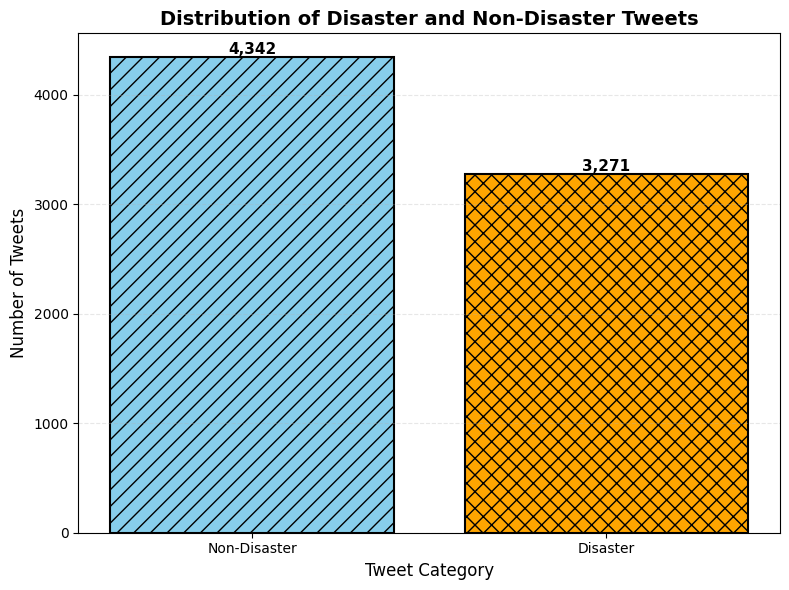

In [14]:
import matplotlib.pyplot as plt

# Get target counts
target_counts = df["target"].value_counts().sort_index()

plt.figure(figsize=(8, 6))

bars = plt.bar(
    ["Non-Disaster", "Disaster"],
    target_counts.values,
    color=["skyblue", "orange"],
    edgecolor="black",
    linewidth=1.5
)

# Add different patterns
bars[0].set_hatch("//")     # Non-disaster
bars[1].set_hatch("xx")     # Disaster

# Add values on top of bars
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{int(height):,}",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold"
    )

plt.title(
    "Distribution of Disaster and Non-Disaster Tweets",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Tweet Category", fontsize=12)
plt.ylabel("Number of Tweets", fontsize=12)

plt.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

## <span style="color:LIGHTpink"><b>Visualize disaster vs non-disaster tweets</b></span>

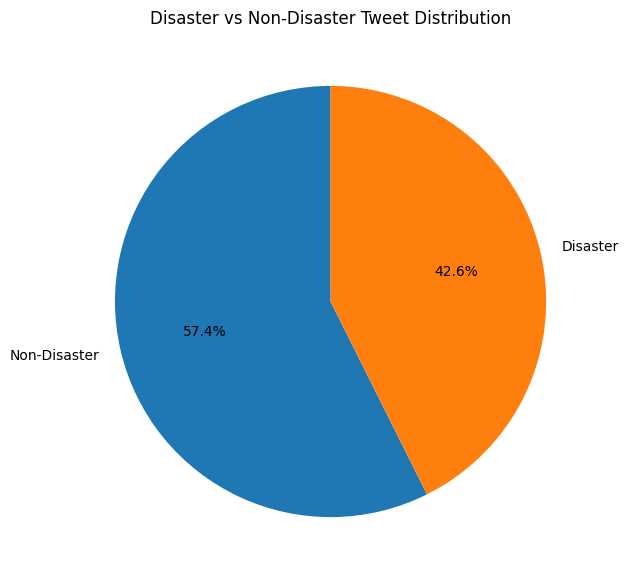

In [59]:
class_counts = df["target"].value_counts()

plt.figure(figsize=(7, 7))

plt.pie(
    class_counts,
    labels=["Non-Disaster", "Disaster"],
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Disaster vs Non-Disaster Tweet Distribution")

plt.show()

## <span style="color:LIGHTpink"><b>Missing Values</b></span>

In [15]:
missing = df.isnull().sum()

missing = missing[missing > 0]

print("Missing values:")
print(missing)

Missing values:
keyword       61
location    2534
dtype: int64


In [16]:
missing_percentage = (df.isnull().sum() / len(df)) * 100

print(missing_percentage.sort_values(ascending=False))

location    33.285170
keyword      0.801261
id           0.000000
text         0.000000
target       0.000000
dtype: float64


In [17]:
df["text"] = df["text"].fillna("")

print("Missing text values:", df["text"].isnull().sum())

Missing text values: 0


## <span style="color:LIGHTpink"><b>Duplicate Values</b></span>

In [18]:
print("Duplicate tweets:", df["text"].duplicated().sum())

Duplicate tweets: 110


## <span style="color:LIGHTpink"><b>Duplicate Removal</b></span>

In [19]:
df = df.drop_duplicates(subset="text")

print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (7503, 5)


## <span style="color:LIGHTpink"><b>Explore the target/class column</b></span>

In [37]:
print(df["target"].value_counts())

target
0    4305
1    3198
Name: count, dtype: int64


In [38]:
print(
    df["target"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

target
0    57.38
1    42.62
Name: proportion, dtype: float64


## <span style="color:LIGHTpink"><b>Text Cleaning</b></span>

In [71]:
import re

def clean_text(text):
    text = str(text)
    
    # Convert to lowercase
    text = text.lower()

    # Remove email addresses
    text = re.sub(r"\S+@\S+", "", text)


    # Remove URLs
    text = re.sub(r"http\S+|www\S+|https\S+", "", text)
    
    # Remove mentions
    text = re.sub(r"@\w+", "", text)
    
    # Remove hashtag symbol but keep the word
    text = re.sub(r"#", "", text)
    
    # Remove punctuation and special characters
    text = re.sub(r"[^a-zA-Z\s]", "", text)
    
    # Remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()
    
    return text


## <span style="color:LIGHTpink"><b>Examine the Tweet text</b></span>

In [72]:
# Tokenize cleaned tweets into individual words
df["tokens"] = df["clean_text"].apply(lambda text: text.split())

# Display the results
display(df[["clean_text", "tokens"]].head(10))

,clean_text,tokens
0,our deeds are the reason of this earthquake ma...,"[our, deeds, are, the, reason, of, this, earth..."
1,forest fire near la ronge sask canada,"[forest, fire, near, la, ronge, sask, canada]"
2,all residents asked to shelter in place are be...,"[all, residents, asked, to, shelter, in, place..."
3,people receive wildfires evacuation orders in ...,"[people, receive, wildfires, evacuation, order..."
4,just got sent this photo from ruby alaska as s...,"[just, got, sent, this, photo, from, ruby, ala..."
5,rockyfire update california hwy closed in both...,"[rockyfire, update, california, hwy, closed, i..."
6,flood disaster heavy rain causes flash floodin...,"[flood, disaster, heavy, rain, causes, flash, ..."
7,i m on top of the hill and i can see a fire in...,"[i, m, on, top, of, the, hill, and, i, can, se..."
8,there s an emergency evacuation happening now ...,"[there, s, an, emergency, evacuation, happenin..."
9,i m afraid that the tornado is coming to our area,"[i, m, afraid, that, the, tornado, is, coming,..."


In [43]:
print(df.columns)

Index(['id', 'keyword', 'location', 'text', 'target', 'clean_text'], dtype='object')


In [21]:
df["clean_text"] = df["text"].apply(clean_text)

display(df[["text", "clean_text"]].head(10))

,text,clean_text
0,Our Deeds are the Reason of this #earthquake M...,our deeds are the reason of this earthquake ma...
1,Forest fire near La Ronge Sask. Canada,forest fire near la ronge sask canada
2,All residents asked to 'shelter in place' are ...,all residents asked to shelter in place are be...
3,"13,000 people receive #wildfires evacuation or...",people receive wildfires evacuation orders in ...
4,Just got sent this photo from Ruby #Alaska as ...,just got sent this photo from ruby alaska as s...
5,#RockyFire Update => California Hwy. 20 closed...,rockyfire update california hwy closed in both...
6,#flood #disaster Heavy rain causes flash flood...,flood disaster heavy rain causes flash floodin...
7,I'm on top of the hill and I can see a fire in...,im on top of the hill and i can see a fire in ...
8,There's an emergency evacuation happening now ...,theres an emergency evacuation happening now i...
9,I'm afraid that the tornado is coming to our a...,im afraid that the tornado is coming to our area


In [44]:
df["tweet_length"] = df["text"].astype(str).apply(len)

print(df["tweet_length"].describe())

count    7503.000000
mean      100.861389
std        33.818107
min         7.000000
25%        77.000000
50%       107.000000
75%       133.000000
max       157.000000
Name: tweet_length, dtype: float64


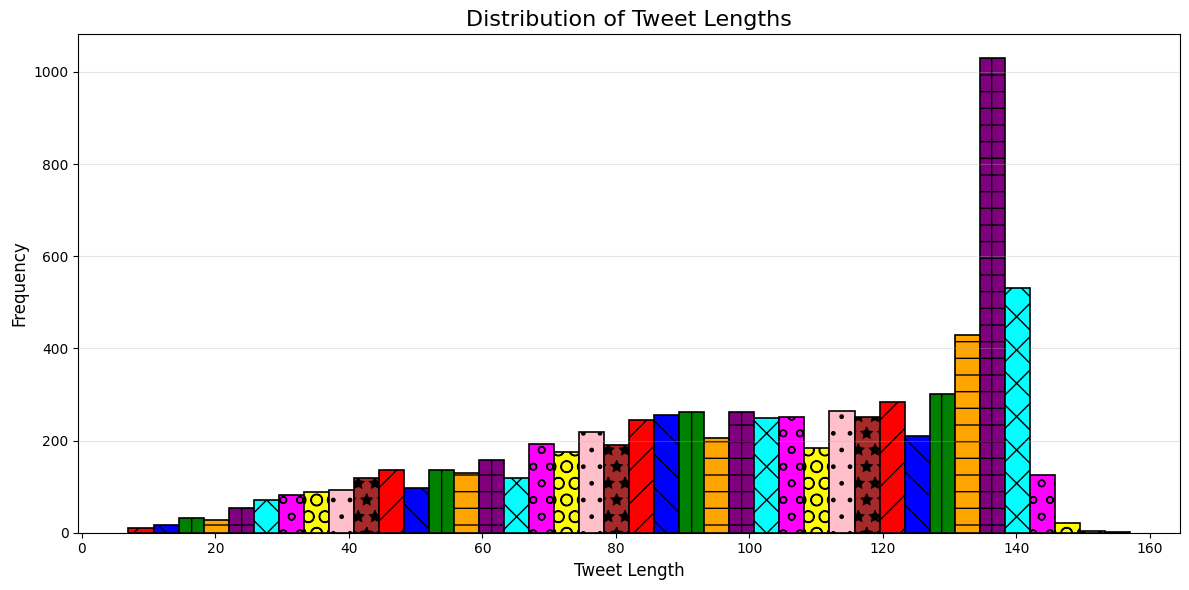

In [60]:
plt.figure(figsize=(12, 6))

# Create histogram
counts, bins, patches = plt.hist(
    df["tweet_length"],
    bins=40,
    edgecolor="black",
    linewidth=1.2
)

# Different colours and patterns
colors = [
    "red", "blue", "green", "orange", "purple",
    "cyan", "magenta", "yellow", "pink", "brown"
]

patterns = [
    "/", "\\", "|", "-", "+",
    "x", "o", "O", ".", "*"
]

# Apply colours and patterns repeatedly
for i, patch in enumerate(patches):
    patch.set_facecolor(colors[i % len(colors)])
    patch.set_hatch(patterns[i % len(patterns)])

plt.title("Distribution of Tweet Lengths", fontsize=16)
plt.xlabel("Tweet Length", fontsize=12)
plt.ylabel("Frequency", fontsize=12)

plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

## <span style="color:LIGHTpink"><b>Remove Empty Tweets</b></span>

In [22]:
df = df[df["clean_text"].str.len() > 0]

print("Dataset shape after cleaning:", df.shape)

Dataset shape after cleaning: (7503, 6)


## <span style="color:LIGHTpink"><b>Find the most common words in disaster tweets</b></span>

In [47]:
disaster_tweets = df[df["target"] == 1]["clean_text"]

In [48]:
all_disaster_text = " ".join(disaster_tweets)

In [49]:
words = all_disaster_text.split()

print("Total words:", len(words))

Total words: 44451


In [51]:
word_counts = Counter(words)

common_words = word_counts.most_common(20)

common_words

[('the', 1336),
 ('in', 1139),
 ('a', 934),
 ('of', 894),
 ('to', 745),
 ('and', 497),
 ('on', 410),
 ('s', 402),
 ('i', 392),
 ('for', 387),
 ('is', 344),
 ('at', 302),
 ('by', 274),
 ('from', 235),
 ('it', 231),
 ('that', 207),
 ('this', 181),
 ('fire', 177),
 ('after', 173),
 ('was', 167)]

## <span style="color:LIGHTpink"><b>Remove common stopwords</b></span>

In [52]:
stop_words = {
    "the", "a", "an", "and", "or", "is", "are",
    "to", "of", "in", "on", "for", "with",
    "this", "that", "it", "was", "be", "as",
    "at", "by", "from", "i", "you", "we",
    "he", "she", "they", "my", "your", "our",
    "but", "have", "has", "had", "not", "so",
    "im", "its", "rt"
}

filtered_words = [
    word for word in words
    if word not in stop_words and len(word) > 2
]

word_counts = Counter(filtered_words)

common_words = word_counts.most_common(20)

common_words

[('fire', 177),
 ('after', 173),
 ('news', 144),
 ('amp', 134),
 ('more', 123),
 ('via', 119),
 ('disaster', 116),
 ('over', 115),
 ('california', 114),
 ('police', 108),
 ('when', 107),
 ('suicide', 106),
 ('people', 102),
 ('who', 98),
 ('killed', 95),
 ('like', 93),
 ('hiroshima', 93),
 ('were', 92),
 ('storm', 89),
 ('just', 88)]

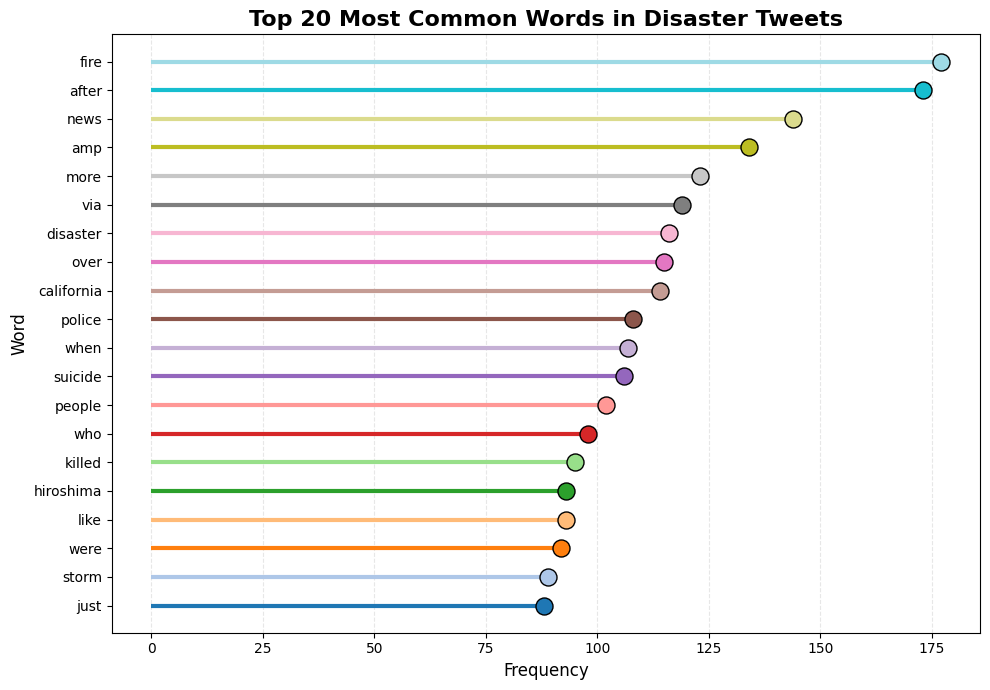

In [64]:
words_df = pd.DataFrame(
    common_words,
    columns=["Word", "Frequency"]
).sort_values("Frequency")

plt.figure(figsize=(10, 7))

# Generate different colours
colors = plt.cm.tab20(np.linspace(0, 1, len(words_df)))

# Draw each lollipop with a different colour
for i, (_, row) in enumerate(words_df.iterrows()):
    
    # Stem
    plt.hlines(
        y=row["Word"],
        xmin=0,
        xmax=row["Frequency"],
        color=colors[i],
        linewidth=3
    )
    
    # Circle
    plt.scatter(
        row["Frequency"],
        row["Word"],
        s=150,
        color=colors[i],
        edgecolor="black",
        linewidth=1,
        zorder=3
    )

plt.title(
    "Top 20 Most Common Words in Disaster Tweets",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Frequency", fontsize=12)
plt.ylabel("Word", fontsize=12)

plt.grid(
    axis="x",
    linestyle="--",
    alpha=0.3
)

plt.tight_layout()
plt.show()

In [55]:
vectorizer = CountVectorizer(
    stop_words="english",
    ngram_range=(2, 2),
    min_df=2
)

bigram_matrix = vectorizer.fit_transform(disaster_tweets)

bigram_counts = np.asarray(
    bigram_matrix.sum(axis=0)
).ravel()

bigrams = vectorizer.get_feature_names_out()

bigram_df = pd.DataFrame({
    "Phrase": bigrams,
    "Frequency": bigram_counts
})

bigram_df = bigram_df.sort_values(
    by="Frequency",
    ascending=False
).head(20)

bigram_df

,Phrase,Frequency
1882,suicide bomber,54
1366,northern california,41
1403,oil spill,38
283,california wildfire,34
1883,suicide bombing,34
259,burning buildings,31
903,homes razed,29
1095,latest homes,28
1579,razed northern,28
1751,severe thunderstorm,27


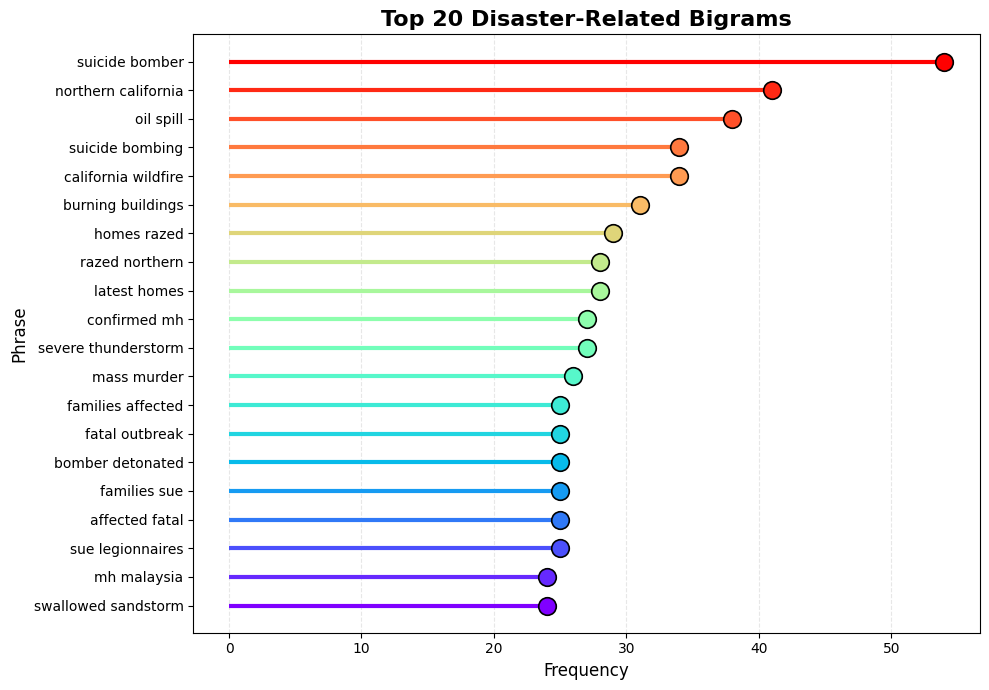

In [65]:
plt.figure(figsize=(10, 7))

# Sort phrases by frequency
bigram_plot = bigram_df.sort_values("Frequency")

# Generate different colours
colors = plt.cm.rainbow(
    np.linspace(0, 1, len(bigram_plot))
)

# Create lollipops
for i, (_, row) in enumerate(bigram_plot.iterrows()):

    # Stem
    plt.hlines(
        y=i,
        xmin=0,
        xmax=row["Frequency"],
        color=colors[i],
        linewidth=3
    )

    # Circle
    plt.scatter(
        row["Frequency"],
        i,
        color=colors[i],
        s=160,
        edgecolor="black",
        linewidth=1.2,
        zorder=3
    )

# Y-axis labels
plt.yticks(
    range(len(bigram_plot)),
    bigram_plot["Phrase"]
)

plt.title(
    "Top 20 Disaster-Related Bigrams",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Frequency", fontsize=12)
plt.ylabel("Phrase", fontsize=12)

plt.grid(
    axis="x",
    linestyle="--",
    alpha=0.3
)

plt.tight_layout()
plt.show()

In [57]:
vectorizer_tri = CountVectorizer(
    stop_words="english",
    ngram_range=(3, 3),
    min_df=2
)

trigram_matrix = vectorizer_tri.fit_transform(disaster_tweets)

trigram_counts = np.asarray(
    trigram_matrix.sum(axis=0)
).ravel()

trigrams = vectorizer_tri.get_feature_names_out()

trigram_df = pd.DataFrame({
    "Phrase": trigrams,
    "Frequency": trigram_counts
})

trigram_df = trigram_df.sort_values(
    by="Frequency",
    ascending=False
).head(20)

trigram_df

,Phrase,Frequency
984,northern california wildfire,29
779,latest homes razed,28
634,homes razed northern,28
1151,razed northern california,27
1388,suicide bomber detonated,25
481,families sue legionnaires,25
480,families affected fatal,25
21,affected fatal outbreak,25
1387,sue legionnaires families,24
32,airport swallowed sandstorm,24


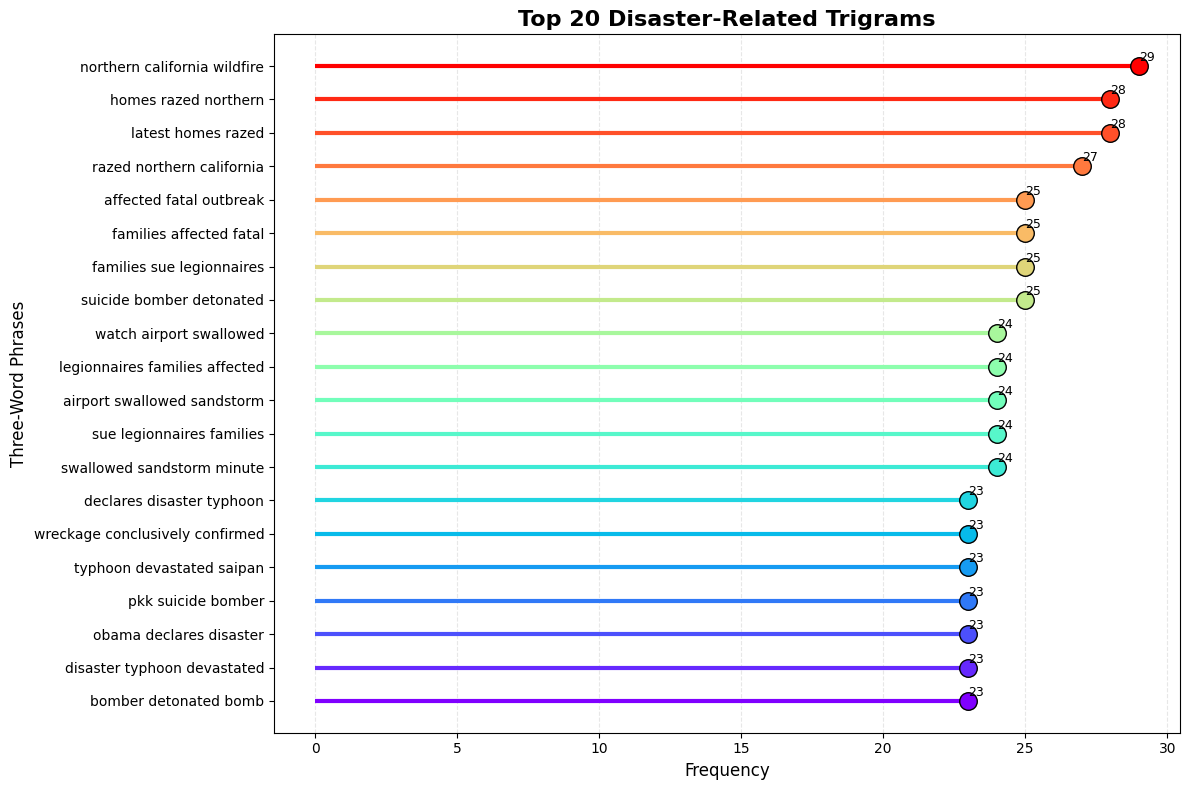

In [66]:
plt.figure(figsize=(12, 8))

# Sort trigrams by frequency
trigram_plot = trigram_df.sort_values("Frequency")

# Generate different colours
colors = plt.cm.rainbow(
    np.linspace(0, 1, len(trigram_plot))
)

# Draw each lollipop in a different colour
for i, (_, row) in enumerate(trigram_plot.iterrows()):

    # Lollipop stem
    plt.hlines(
        y=i,
        xmin=0,
        xmax=row["Frequency"],
        color=colors[i],
        linewidth=3
    )

    # Lollipop circle
    plt.scatter(
        row["Frequency"],
        i,
        color=colors[i],
        s=160,
        edgecolor="black",
        linewidth=1,
        zorder=3
    )

    # Display frequency beside each circle
    plt.text(
        row["Frequency"],
        i + 0.15,
        str(row["Frequency"]),
        fontsize=9
    )

# Set phrase labels
plt.yticks(
    range(len(trigram_plot)),
    trigram_plot["Phrase"]
)

plt.title(
    "Top 20 Disaster-Related Trigrams",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Frequency", fontsize=12)
plt.ylabel("Three-Word Phrases", fontsize=12)

plt.grid(
    axis="x",
    linestyle="--",
    alpha=0.3
)

plt.tight_layout()
plt.show()

 ## <span style="color:green"><b>Final summary for my report</b></span>
This is the final findings of Part 1, Task 1 - Data Exploration which includes the following:

Data Exploration: The dataset contains approximately 10,000 hand-classified tweets, where each tweet is labelled as either disaster (1) or non-disaster (0). Pandas was used to examine the dataset structure, column names, data types, missing values, and duplicate records. The class distribution was visualized using bar and pie charts to compare disaster and non-disaster tweets. The tweet text was cleaned by removing URLs, mentions, punctuation, and unnecessary characters. Word-frequency analysis was then performed on disaster tweets to identify the most commonly occurring keywords. Bigram and trigram analysis was also used to identify frequently occurring disaster-related phrases. These exploratory findings help identify important textual patterns that can later be used for NLP feature engineering and disaster tweet classification.


## <span style="color:LIGHTpink"><b> Task 2: Data Preparation</b></span>


## <span style="color:LIGHTpink"><b>Work Frequency Analysis</b></span>

## Install nltk:

In [23]:
%pip install nltk

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: C:\Users\hp\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [24]:
import nltk

nltk.download("stopwords")

print("✅ NLTK installed successfully!")

✅ NLTK installed successfully!


[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\hp\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


## Then:

In [25]:
from nltk.corpus import stopwords

stop_words = set(stopwords.words("english"))

words = " ".join(df["clean_text"]).split()

filtered_words = [
    word for word in words
    if word not in stop_words
]

print("Total words:", len(words))
print("Words after removing stopwords:", len(filtered_words))

Total words: 100336
Words after removing stopwords: 65619


## <span style="color:LIGHTpink"><b>Most Common Words</b></span>

In [26]:
from collections import Counter

word_counts = Counter(filtered_words)

common_words = word_counts.most_common(20)

print("Top 20 most common words:")

for word, count in common_words:
    print(f"{word}: {count}")

Top 20 most common words:
like: 342
im: 301
amp: 298
fire: 247
get: 229
new: 225
via: 217
dont: 203
news: 194
one: 193
people: 190
us: 170
video: 161
emergency: 156
disaster: 148
police: 139
would: 129
still: 128
body: 125
time: 123


## <span style="color:LIGHTpink"><b>Plot Common Words</b></span>

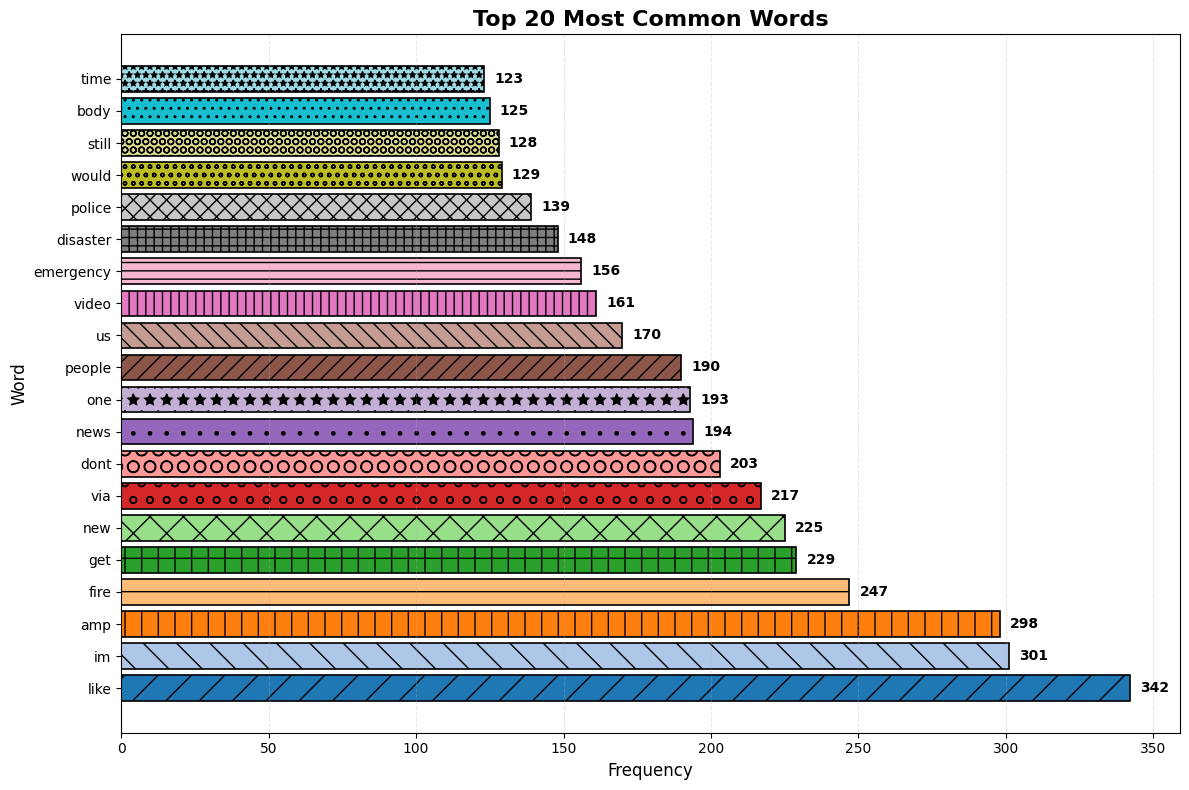

In [27]:
import matplotlib.pyplot as plt
import numpy as np

words_df = pd.DataFrame(
    common_words,
    columns=["Word", "Frequency"]
)

# 20 different colors
colors = plt.cm.tab20(np.linspace(0, 1, len(words_df)))

# Different hatch patterns
patterns = [
    "/", "\\", "|", "-", "+",
    "x", "o", "O", ".", "*",
    "//", "\\\\", "||", "--", "++",
    "xx", "oo", "OO", "..", "**"
]

plt.figure(figsize=(12, 8))

bars = plt.barh(
    words_df["Word"],
    words_df["Frequency"],
    color=colors,
    edgecolor="black",
    linewidth=1.2
)

# Apply different pattern to every bar
for bar, pattern in zip(bars, patterns):
    bar.set_hatch(pattern)

# Add frequency values at the end of each bar
for bar in bars:
    width = bar.get_width()
    
    plt.text(
        width + max(words_df["Frequency"]) * 0.01,
        bar.get_y() + bar.get_height() / 2,
        f"{int(width):,}",
        va="center",
        fontsize=10,
        fontweight="bold"
    )

plt.title(
    "Top 20 Most Common Words",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Frequency", fontsize=12)
plt.ylabel("Word", fontsize=12)

plt.grid(
    axis="x",
    linestyle="--",
    alpha=0.3
)

plt.tight_layout()
plt.show()

## <span style="color:LIGHTpink"><b>Convert labels into numerical format</b></span>

In [73]:
print("Unique target labels:", df["target"].unique())

print("\nTarget distribution:")
print(df["target"].value_counts())

Unique target labels: [1 0]

Target distribution:
target
0    4305
1    3198
Name: count, dtype: int64


In [74]:
df["target"] = pd.to_numeric(df["target"], errors="raise").astype(int)

# Validate the labels
assert set(df["target"].unique()).issubset({0, 1})

print("Labels converted and validated successfully.")
display(df[["clean_text", "target"]].head(10))

Labels converted and validated successfully.


,clean_text,target
0,our deeds are the reason of this earthquake ma...,1
1,forest fire near la ronge sask canada,1
2,all residents asked to shelter in place are be...,1
3,people receive wildfires evacuation orders in ...,1
4,just got sent this photo from ruby alaska as s...,1
5,rockyfire update california hwy closed in both...,1
6,flood disaster heavy rain causes flash floodin...,1
7,i m on top of the hill and i can see a fire in...,1
8,there s an emergency evacuation happening now ...,1
9,i m afraid that the tornado is coming to our area,1


## <span style="color:LIGHTpink"><b>Create X and Y</b></span>

In [28]:
X = df["clean_text"]
y = df["target"]

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

X shape: (7503,)
y shape: (7503,)

Target distribution:
target
0    4305
1    3198
Name: count, dtype: int64


## <span style="color:LIGHTpink"><b>Train Test-Split</b></span>

In [29]:
# ==========================================
# PREPARE DATA FOR NLP MODEL
# ==========================================

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

# Check that required columns exist
print("Available columns:")
print(df.columns.tolist())

# Input and target
X = df["clean_text"]
y = df["target"]

print("\nX shape:", X.shape)
print("y shape:", y.shape)

# ==========================================
# TRAIN / TEST SPLIT
# ==========================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))

# ==========================================
# TF-IDF VECTORIZATION
# ==========================================

tfidf = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("\n✅ TF-IDF completed!")
print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)

Available columns:
['id', 'keyword', 'location', 'text', 'target', 'clean_text']

X shape: (7503,)
y shape: (7503,)

Training samples: 6002
Testing samples: 1501

✅ TF-IDF completed!
Training TF-IDF shape: (6002, 10000)
Testing TF-IDF shape: (1501, 10000)


## <span style="color:LIGHTpink"><b>Visualize the training and testing distribution</b></span>

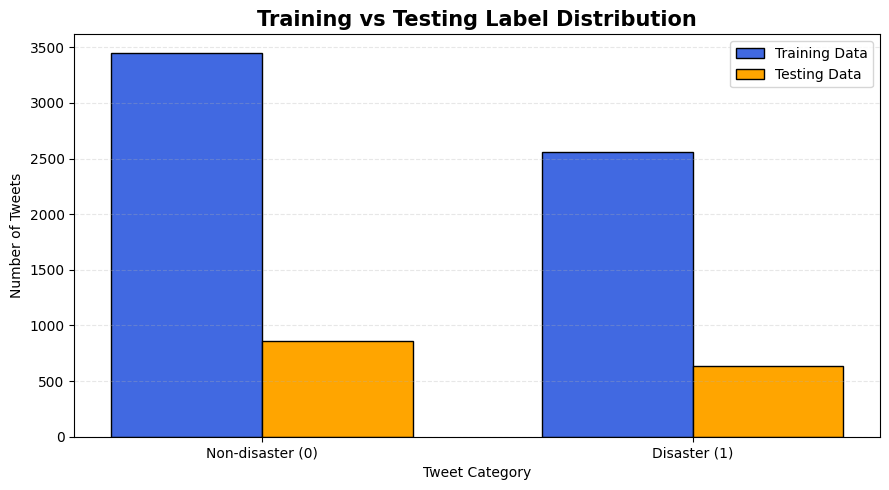

In [75]:
import matplotlib.pyplot as plt

train_counts = y_train.value_counts().sort_index()
test_counts = y_test.value_counts().sort_index()

labels = ["Non-disaster (0)", "Disaster (1)"]

x = np.arange(len(labels))
width = 0.35

plt.figure(figsize=(9, 5))

plt.bar(
    x - width / 2,
    [train_counts.get(0, 0), train_counts.get(1, 0)],
    width,
    label="Training Data",
    color="royalblue",
    edgecolor="black"
)

plt.bar(
    x + width / 2,
    [test_counts.get(0, 0), test_counts.get(1, 0)],
    width,
    label="Testing Data",
    color="orange",
    edgecolor="black"
)

plt.title("Training vs Testing Label Distribution", fontsize=15, fontweight="bold")
plt.xlabel("Tweet Category")
plt.ylabel("Number of Tweets")
plt.xticks(x, labels)
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

## <span style="color:LIGHTpink"><b>Save the prepared dataset</b></span>

In [76]:
# Save the cleaned dataset
df.to_csv("twitter_disaster_cleaned.csv", index=False)

# Save training and testing data
train_df = pd.DataFrame({
    "clean_text": X_train,
    "target": y_train
})

test_df = pd.DataFrame({
    "clean_text": X_test,
    "target": y_test
})

train_df.to_csv("twitter_disaster_train.csv", index=False)
test_df.to_csv("twitter_disaster_test.csv", index=False)

print("Files saved successfully:")
print("1. twitter_disaster_cleaned.csv")
print("2. twitter_disaster_train.csv")
print("3. twitter_disaster_test.csv")

Files saved successfully:
1. twitter_disaster_cleaned.csv
2. twitter_disaster_train.csv
3. twitter_disaster_test.csv


## <span style="color:LIGHTpink"><b>Train Logistic Regression</b></span>

In [30]:
# ==========================================
# LOGISTIC REGRESSION MODEL
# ==========================================

from sklearn.linear_model import LogisticRegression

model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

model.fit(X_train_tfidf, y_train)

print("✅ Logistic Regression model trained successfully!")

✅ Logistic Regression model trained successfully!


## <span style="color:LIGHTpink"><b>Make Predictions</b></span>

In [31]:
y_pred = model.predict(X_test_tfidf)

print("Predictions completed!")
print(y_pred[:20])

Predictions completed!
[0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 1 1 0 1 1]


## <span style="color:GREEN"><b>Part 2: Feature Engineering and Model Selection</b></span>

## <span style="color:Lightpink"><b>Task 3: Feature Engineering</b></span>

## <span style="color:Lightpink"><b>Extract word-frequency features</b></span>

In [78]:
# Create a Bag-of-Words vectorizer
count_vectorizer = CountVectorizer(
    max_features=5000,
    ngram_range=(1, 2),
    min_df=2
)

# Learn vocabulary from training data
X_train_bow = count_vectorizer.fit_transform(X_train)

# Transform testing data
X_test_bow = count_vectorizer.transform(X_test)

print("Training Bag-of-Words shape:", X_train_bow.shape)
print("Testing Bag-of-Words shape:", X_test_bow.shape)

Training Bag-of-Words shape: (6002, 5000)
Testing Bag-of-Words shape: (1501, 5000)


In [79]:
word_counts = np.asarray(X_train_bow.sum(axis=0)).ravel()

words = count_vectorizer.get_feature_names_out()

word_frequency_df = pd.DataFrame({
    "Word": words,
    "Frequency": word_counts
})

word_frequency_df = word_frequency_df.sort_values(
    "Frequency",
    ascending=False
).head(20)

display(word_frequency_df)

,Word,Frequency
4083,the,2564
2020,in,1570
4301,to,1548
2940,of,1444
160,and,1101
2159,is,729
1532,for,695
3028,on,677
4950,you,624
2781,my,541


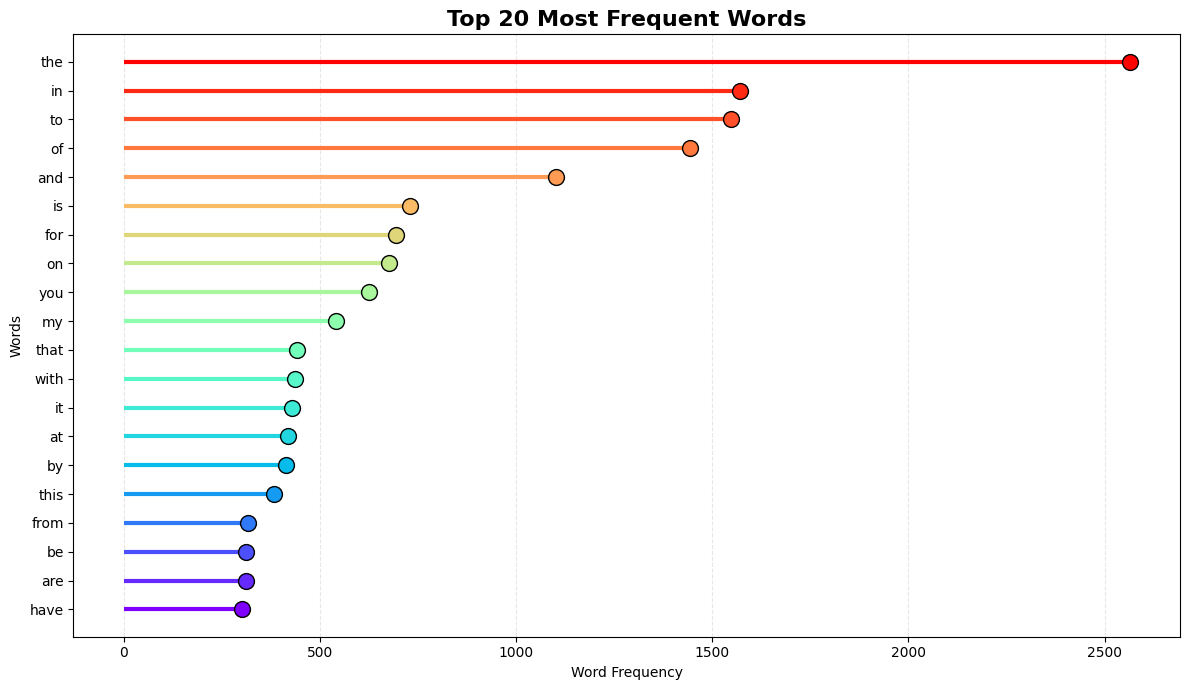

In [81]:
plt.figure(figsize=(12, 7))

plot_df = word_frequency_df.sort_values("Frequency")

colors = plt.cm.rainbow(
    np.linspace(0, 1, len(plot_df))
)

for i, (_, row) in enumerate(plot_df.iterrows()):
    plt.hlines(
        y=i,
        xmin=0,
        xmax=row["Frequency"],
        color=colors[i],
        linewidth=3
    )

    plt.scatter(
        row["Frequency"],
        i,
        color=colors[i],
        s=130,
        edgecolor="black",
        zorder=3
    )

plt.yticks(range(len(plot_df)), plot_df["Word"])
plt.title("Top 20 Most Frequent Words", fontsize=16, fontweight="bold")
plt.xlabel("Word Frequency")
plt.ylabel("Words")
plt.grid(axis="x", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

Interpretation: This visualization identifies the words that occur most frequently in the training tweets. Frequent words are not necessarily the most useful words for classification, which is why TF-IDF is also important.

## <span style="color:LIGHTpink"><b>Extract TF-IDF features</b></span>

In [82]:
tfidf_vectorizer = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2),
    min_df=2,
    sublinear_tf=True
)

X_train_tfidf = tfidf_vectorizer.fit_transform(X_train)

X_test_tfidf = tfidf_vectorizer.transform(X_test)

print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)

Training TF-IDF shape: (6002, 10000)
Testing TF-IDF shape: (1501, 10000)


In [83]:
feature_names = tfidf_vectorizer.get_feature_names_out()

average_tfidf = np.asarray(
    X_train_tfidf.mean(axis=0)
).ravel()

tfidf_df = pd.DataFrame({
    "Word": feature_names,
    "Average_TFIDF": average_tfidf
})

tfidf_df = tfidf_df.sort_values(
    "Average_TFIDF",
    ascending=False
).head(20)

display(tfidf_df)

,Word,Average_TFIDF
8638,the,0.032087
3977,in,0.023889
8975,to,0.023263
5964,of,0.022075
241,and,0.019261
4189,is,0.014923
6231,on,0.014182
3005,for,0.014109
9903,you,0.013422
5526,my,0.012167


In [85]:
def extract_tweet_features(text):
    text = str(text)

    return pd.Series({
        "tweet_length": len(text),
        "word_count": len(text.split()),
        "hashtag_count": len(re.findall(r"#\w+", text)),
        "mention_count": len(re.findall(r"@\w+", text)),
        "url_count": len(re.findall(
            r"https?://\S+|www\.\S+",
            text
        )),
        "exclamation_count": text.count("!"),
        "question_count": text.count("?"),
        "uppercase_count": sum(
            1 for char in text if char.isupper()
        )
    })


# Extract features from the original tweets
additional_features = df["text"].apply(
    extract_tweet_features
)

# Add the extracted features to the dataset
df = pd.concat(
    [df, additional_features],
    axis=1
)

display(
    df[
        [
            "text",
            "tweet_length",
            "word_count",
            "hashtag_count",
            "mention_count",
            "url_count",
            "exclamation_count"
        ]
    ].head(10)
)

,text,tweet_length,tweet_length,word_count,hashtag_count,mention_count,url_count,exclamation_count
0,Our Deeds are the Reason of this #earthquake M...,69,69,13,1,0,0,0
1,Forest fire near La Ronge Sask. Canada,38,38,7,0,0,0,0
2,All residents asked to 'shelter in place' are ...,133,133,22,0,0,0,0
3,"13,000 people receive #wildfires evacuation or...",65,65,8,1,0,0,0
4,Just got sent this photo from Ruby #Alaska as ...,87,87,16,2,0,0,0
5,#RockyFire Update => California Hwy. 20 closed...,110,110,18,3,0,0,0
6,#flood #disaster Heavy rain causes flash flood...,95,95,14,2,0,0,0
7,I'm on top of the hill and I can see a fire in...,59,59,15,0,0,0,0
8,There's an emergency evacuation happening now ...,79,79,12,0,0,0,0
9,I'm afraid that the tornado is coming to our a...,52,52,10,0,0,0,0


## <span style="color:LIGHTpink"><b>Perform sentiment analysis</b></span>

In [86]:
%pip install vaderSentiment

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: C:\Users\hp\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [87]:
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

sentiment_analyzer = SentimentIntensityAnalyzer()

def get_sentiment(text):
    scores = sentiment_analyzer.polarity_scores(str(text))

    return pd.Series({
        "sentiment_positive": scores["pos"],
        "sentiment_negative": scores["neg"],
        "sentiment_neutral": scores["neu"],
        "sentiment_compound": scores["compound"]
    })


sentiment_features = df["text"].apply(get_sentiment)

df = pd.concat(
    [df, sentiment_features],
    axis=1
)

display(
    df[
        [
            "text",
            "sentiment_positive",
            "sentiment_negative",
            "sentiment_neutral",
            "sentiment_compound"
        ]
    ].head(10)
)

,text,sentiment_positive,sentiment_negative,sentiment_neutral,sentiment_compound
0,Our Deeds are the Reason of this #earthquake M...,0.149,0.000,0.851,0.2732
1,Forest fire near La Ronge Sask. Canada,0.000,0.286,0.714,-0.3400
2,All residents asked to 'shelter in place' are ...,0.000,0.095,0.905,-0.2960
3,"13,000 people receive #wildfires evacuation or...",0.000,0.000,1.000,0.0000
4,Just got sent this photo from Ruby #Alaska as ...,0.000,0.000,1.000,0.0000
5,#RockyFire Update => California Hwy. 20 closed...,0.000,0.124,0.876,-0.3400
6,#flood #disaster Heavy rain causes flash flood...,0.000,0.240,0.760,-0.6249
7,I'm on top of the hill and I can see a fire in...,0.105,0.140,0.756,-0.1531
8,There's an emergency evacuation happening now ...,0.000,0.191,0.809,-0.3818
9,I'm afraid that the tornado is coming to our a...,0.000,0.000,1.000,0.0000


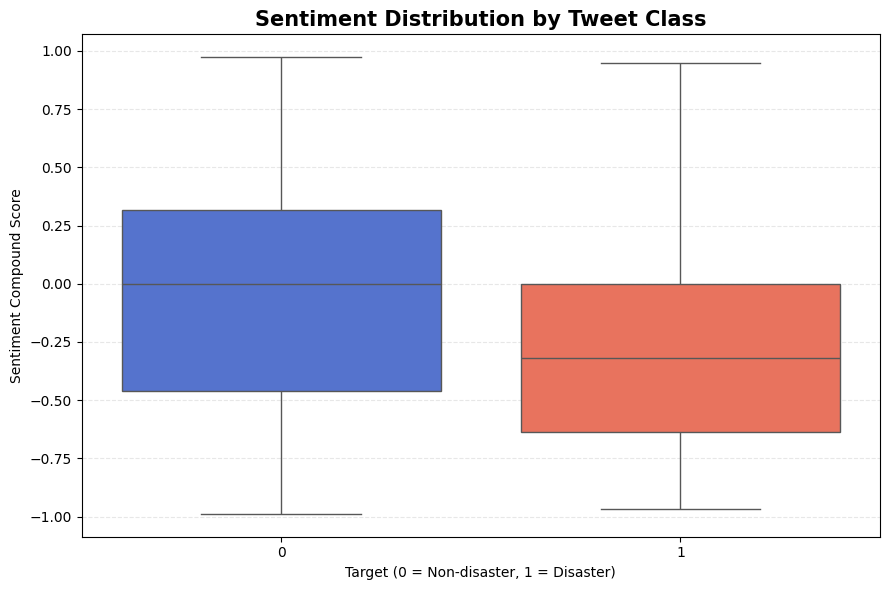

In [88]:
plt.figure(figsize=(9, 6))

sns.boxplot(
    data=df,
    x="target",
    y="sentiment_compound",
    hue="target",
    palette=["royalblue", "tomato"],
    legend=False
)

plt.title("Sentiment Distribution by Tweet Class",
          fontsize=15, fontweight="bold")
plt.xlabel("Target (0 = Non-disaster, 1 = Disaster)")
plt.ylabel("Sentiment Compound Score")
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

Interpretation: The chart compares sentiment scores for disaster and non-disaster tweets. The two groups may overlap, so sentiment should be treated as an additional feature rather than a reliable indicator on its own.

## <span style="color:LIGHTpink"><b>TASK 4: Model Selection and Training</b></span>

We will compare four classification models:

* Logistic Regression.
* Multinomial Naive Bayes.
* Random Forest.
* Linear Support Vector Machine (SVM).

For the initial comparison, we will use TF-IDF features. TF-IDF is a strong starting point for traditional machine-learning models on text classification tasks.

## <span style="color:LIGHTpink"><b>Create the candidate models</b></span>

In [89]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ),

    "Multinomial Naive Bayes": MultinomialNB(),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        max_depth=30,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "Linear SVM": LinearSVC(
        class_weight="balanced",
        random_state=42
    )
}

print("Candidate models:")
for model_name in models:
    print("-", model_name)

Candidate models:
- Logistic Regression
- Multinomial Naive Bayes
- Random Forest
- Linear SVM


## <span style="color:LIGHTpink"><b>Train and evaluate the models using cross-validation</b></span>

In [90]:
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, cross_validate

# Use the training TF-IDF features only
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1"
}

cv_results = []

for model_name, model in models.items():

    print(f"Evaluating {model_name}...")

    scores = cross_validate(
        model,
        X_train_tfidf,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1,
        error_score="raise"
    )

    cv_results.append({
        "Model": model_name,
        "Accuracy": scores["test_accuracy"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1-Score": scores["test_f1"].mean()
    })

results_df = pd.DataFrame(cv_results)

results_df = results_df.sort_values(
    "F1-Score",
    ascending=False
).reset_index(drop=True)

display(results_df.round(4))

Evaluating Logistic Regression...
Evaluating Multinomial Naive Bayes...
Evaluating Random Forest...
Evaluating Linear SVM...


,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.7957,0.7766,0.7310,0.7530
1,Linear SVM,0.7776,0.7495,0.7181,0.7335
2,Multinomial Naive Bayes,0.7924,0.8676,0.6055,0.7131
3,Random Forest,0.7704,0.8035,0.6106,0.6937


Note: Random Forest may take longer because text vectorization can produce thousands of features. Linear SVM and Logistic Regression are often efficient starting points for sparse text data.

## <span style="color:LIGHTpink"><b>Visualize model performance</b></span>

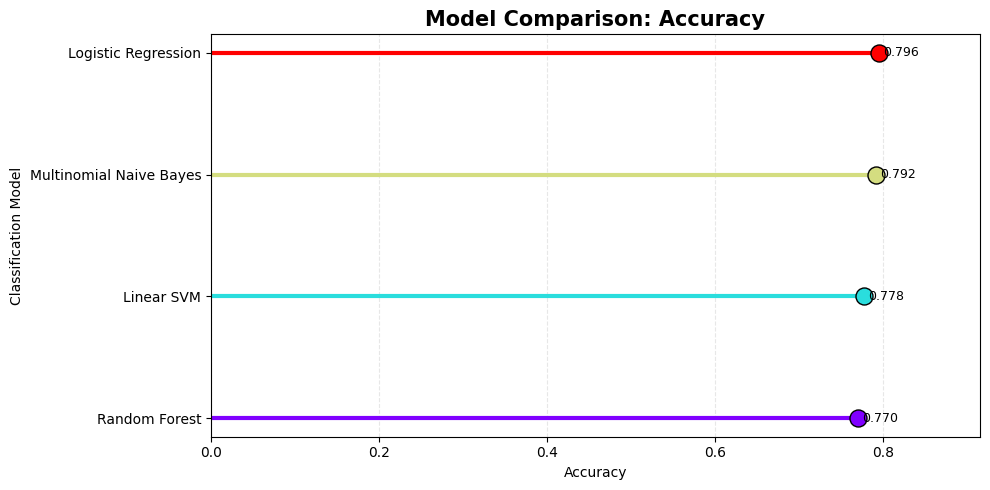

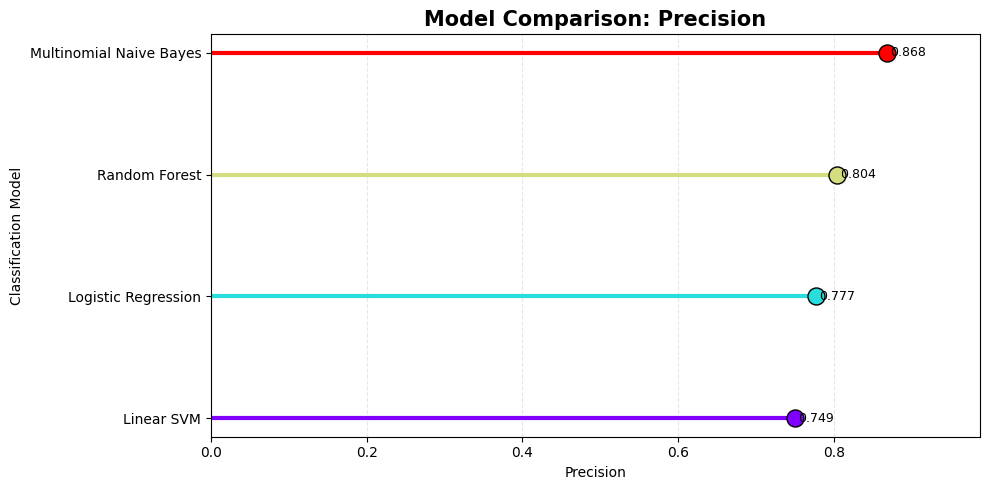

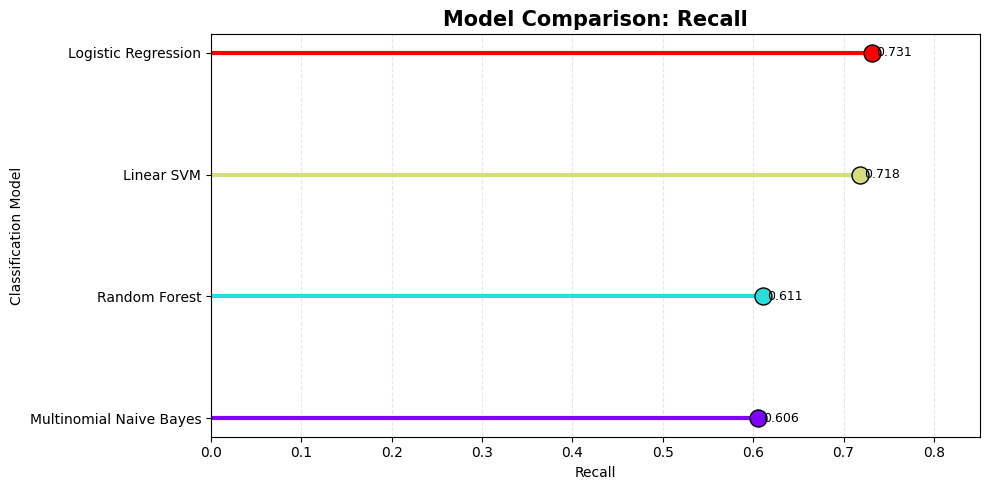

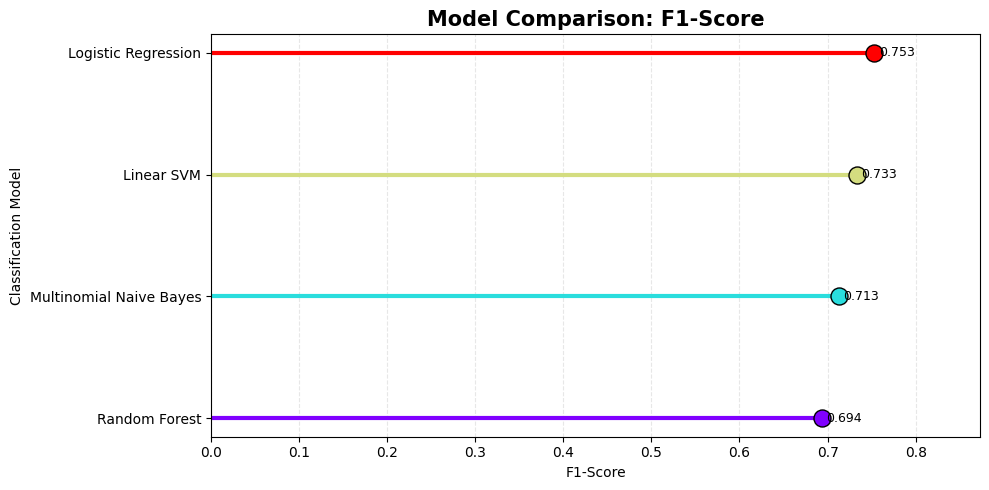

In [91]:
metrics_to_plot = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score"
]

for metric in metrics_to_plot:

    plot_df = results_df.sort_values(metric)

    plt.figure(figsize=(10, 5))

    colors = plt.cm.rainbow(
        np.linspace(0, 1, len(plot_df))
    )

    for i, (_, row) in enumerate(plot_df.iterrows()):

        plt.hlines(
            y=i,
            xmin=0,
            xmax=row[metric],
            color=colors[i],
            linewidth=3
        )

        plt.scatter(
            row[metric],
            i,
            color=colors[i],
            s=150,
            edgecolor="black",
            zorder=3
        )

        plt.text(
            row[metric] + 0.005,
            i,
            f"{row[metric]:.3f}",
            va="center",
            fontsize=9
        )

    plt.yticks(
        range(len(plot_df)),
        plot_df["Model"]
    )

    plt.xlim(0, min(1.1, plot_df[metric].max() + 0.12))

    plt.title(
        f"Model Comparison: {metric}",
        fontsize=15,
        fontweight="bold"
    )

    plt.xlabel(metric)
    plt.ylabel("Classification Model")
    plt.grid(axis="x", linestyle="--", alpha=0.3)
    plt.tight_layout()
    plt.show()

Which metric should you choose?
* Accuracy: Percentage of all predictions that are correct.
* Precision: Of tweets predicted as disasters, how many are actual disaster tweets?
* Recall: Of all actual disaster tweets, how many did the model identify?
* F1-score: A balance between precision and recall.

For disaster-tweet classification, pay particular attention to recall and F1-score, since missing a genuine disaster-related tweet can be important.

## <span style="color:LIGHTpink"><b>Tune Logistic Regression using Grid Search</b></span>
For a reproducible starting point, we will tune Logistic Regression. If another model performs better during cross-validation, you can tune that model instead.

Grid Search evaluates different hyperparameter combinations using cross-validation.

In [92]:
from sklearn.model_selection import GridSearchCV

lr_pipeline = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            max_features=10000,
            ngram_range=(1, 2),
            min_df=2,
            sublinear_tf=True
        )
    ),
    (
        "classifier",
        LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=42
        )
    )
])

param_grid = {
    "tfidf__max_features": [5000, 10000],
    "tfidf__ngram_range": [(1, 1), (1, 2)],
    "classifier__C": [0.1, 1, 10]
}

grid_search = GridSearchCV(
    estimator=lr_pipeline,
    param_grid=param_grid,
    scoring="f1",
    cv=StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    ),
    n_jobs=-1,
    verbose=1,
    refit=True
)

grid_search.fit(X_train, y_train)

print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation F1-Score:")
print(round(grid_search.best_score_, 4))

Fitting 5 folds for each of 12 candidates, totalling 60 fits
Best Parameters:
{'classifier__C': 1, 'tfidf__max_features': 5000, 'tfidf__ngram_range': (1, 1)}

Best Cross-Validation F1-Score:
0.758


Why use a pipeline? 
* The TF-IDF vocabulary is learned separately inside each training fold, preventing information from the validation fold from leaking into the vectorizer.

This search evaluates 12 parameter combinations across five folds, or 60 model fits, so it may take a few minutes.

## <span style="color:LIGHTpink"><b>Evaluate the tuned model on the test set</b></span>

In [93]:
# Retrieve the best fitted model
best_model = grid_search.best_estimator_

# Predict labels for unseen test data
y_pred = best_model.predict(X_test)

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(
    y_test, y_pred, zero_division=0
)
recall = recall_score(
    y_test, y_pred, zero_division=0
)
f1 = f1_score(
    y_test, y_pred, zero_division=0
)

print("FINAL TEST SET RESULTS")
print("=" * 35)
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-Score:  {f1:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Non-disaster", "Disaster"],
        zero_division=0
    )
)

FINAL TEST SET RESULTS
Accuracy:  0.8055
Precision: 0.7816
Recall:    0.7547
F1-Score:  0.7679

Classification Report:
              precision    recall  f1-score   support

Non-disaster       0.82      0.84      0.83       861
    Disaster       0.78      0.75      0.77       640

    accuracy                           0.81      1501
   macro avg       0.80      0.80      0.80      1501
weighted avg       0.80      0.81      0.80      1501



## <span style="color:LIGHTpink"><b>Plot the confusion matrix</b></span>

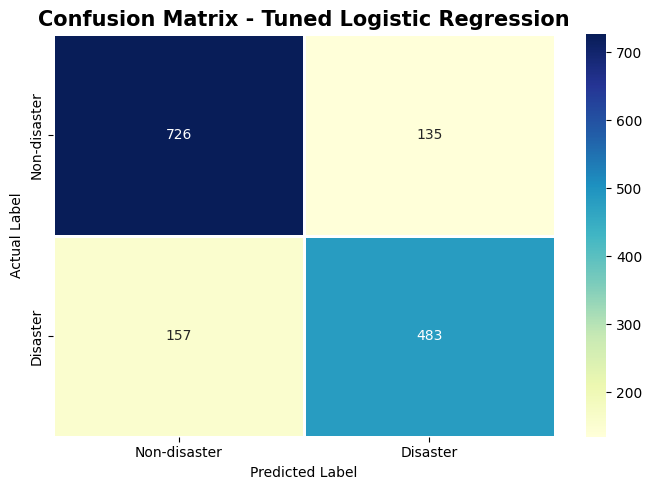

In [94]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=[0, 1]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="YlGnBu",
    linewidths=1,
    xticklabels=["Non-disaster", "Disaster"],
    yticklabels=["Non-disaster", "Disaster"]
)

plt.title("Confusion Matrix - Tuned Logistic Regression",
          fontsize=15, fontweight="bold")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

The confusion matrix shows:

* True negatives: Non-disaster tweets correctly classified.
* True positives: Disaster tweets correctly classified.
* False positives: Non-disaster tweets incorrectly classified as disasters.
* False negatives: Disaster tweets incorrectly classified as non-disasters.

## <span style="color:LIGHTpink"><b>Save the trained model</b></span>

In [95]:
import joblib

joblib.dump(
    best_model,
    "disaster_tweet_classifier.pkl"
)

print("Model saved successfully as disaster_tweet_classifier.pkl")

Model saved successfully as disaster_tweet_classifier.pkl


In [96]:
loaded_model = joblib.load(
    "disaster_tweet_classifier.pkl"
)

sample_tweets = [
    "Massive flooding has damaged several houses",
    "I am enjoying a wonderful day with friends"
]

predictions = loaded_model.predict(sample_tweets)

for tweet, prediction in zip(sample_tweets, predictions):
    label = "Disaster" if prediction == 1 else "Non-disaster"

    print("Tweet:", tweet)
    print("Prediction:", label)
    print("-" * 50)

Tweet: Massive flooding has damaged several houses
Prediction: Disaster
--------------------------------------------------
Tweet: I am enjoying a wonderful day with friends
Prediction: Non-disaster
--------------------------------------------------


## <span style="color:LIGHTpink"><b>Optional: Word2Vec and GloVe embeddings</b></span>

Word2Vec and GloVe represent words as dense numerical vectors that capture semantic relationships. They are useful alternatives to TF-IDF, but they require additional preprocessing and a compatible model architecture.

For your project, I recommend completing the TF-IDF model comparison and evaluation first. Then, if required by your assignment, you can experiment with pre-trained GloVe embeddings or train Word2Vec embeddings and compare their performance against TF-IDF.

### Important note about the additional features: 
 The main model above uses TF-IDF. Although the tweet-length and sentiment features are extracted and visualized, they are not yet combined into the classifier. To evaluate their added value fairly, combine them with TF-IDF in a separate pipeline and compare its cross-validation F1-score against the TF-IDF-only baseline.

## <span style="color:LIGHTpink"><b>Test your model with your own tweet</b></span>

In [34]:
def predict_tweet(tweet):
    cleaned = clean_text(tweet)
    vector = tfidf.transform([cleaned])
    
    prediction = model.predict(vector)[0]
    
    if prediction == 1:
        return "🚨 Disaster-related tweet"
    else:
        return "✅ Not a disaster-related tweet"

In [35]:
predict_tweet("There is a huge earthquake and buildings are collapsing!")

'🚨 Disaster-related tweet'

In [36]:
predict_tweet("I am having a wonderful day with my friends!")

'✅ Not a disaster-related tweet'

## <span style="color:Green"><b>Part 3: Model Evaluation and Validation</b></span>

## <span style="color:Lightpink"><b>Task 5: Model Evaluation</b></span>

## <span style="color:Lightpink"><b>Create the classification models</b></span>

In [98]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ),

    "Multinomial Naive Bayes": MultinomialNB(),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        max_depth=30,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "Linear SVM": LinearSVC(
        class_weight="balanced",
        random_state=42
    )
}

print("Models created successfully.")

Models created successfully.


## <span style="color:Lightpink"><b>Train and evaluate each model</b></span>
We will use a TF-IDF vectorizer inside each model's pipeline. This ensures that the vocabulary is learned from the training data, not the test data.

In [109]:
trained_models = {}
predictions = {}
probability_scores = {}
results = []

for model_name, classifier in models.items():

    print(f"\nTraining {model_name}...")

    pipeline = Pipeline([
        (
            "tfidf",
            TfidfVectorizer(
                max_features=10000,
                ngram_range=(1, 2),
                min_df=2,
                sublinear_tf=True
            )
        ),
        ("classifier", 
         LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=42
        )
    )
])

    # Train model
    pipeline.fit(X_train, y_train)

    # Predict test labels
    y_pred = pipeline.predict(X_test)

    # Obtain continuous scores for ROC and precision-recall curves
    if hasattr(pipeline, "predict_proba"):
        y_score = pipeline.predict_proba(X_test)[:, 1]
    else:
        y_score = pipeline.decision_function(X_test)

    # Store models and predictions
    trained_models[model_name] = pipeline
    predictions[model_name] = y_pred
    probability_scores[model_name] = y_score

    # Calculate evaluation metrics
    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, y_score),
        "Average Precision": average_precision_score(
            y_test, y_score
        )
    })

    print(f"{model_name} completed.")


Training Logistic Regression...
Logistic Regression completed.

Training Multinomial Naive Bayes...
Multinomial Naive Bayes completed.

Training Random Forest...
Random Forest completed.

Training Linear SVM...
Linear SVM completed.


Note: Random Forest may take longer to train because TF-IDF generates thousands of features.

## <span style="color:Lightpink"><b>Compare model performance</b></span>

In [100]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="F1-Score",
    ascending=False
).reset_index(drop=True)

display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,Average Precision
0,Logistic Regression,0.7975,0.7754,0.7391,0.7568,0.8541,0.8531
1,Linear SVM,0.7795,0.7425,0.7391,0.7408,0.8430,0.8319
2,Multinomial Naive Bayes,0.8068,0.8872,0.6266,0.7344,0.8519,0.8593
3,Random Forest,0.7702,0.8092,0.6031,0.6911,0.8136,0.8169


## <span style="color:Lightpink"><b>Visualize the evaluation metrics</b></span>

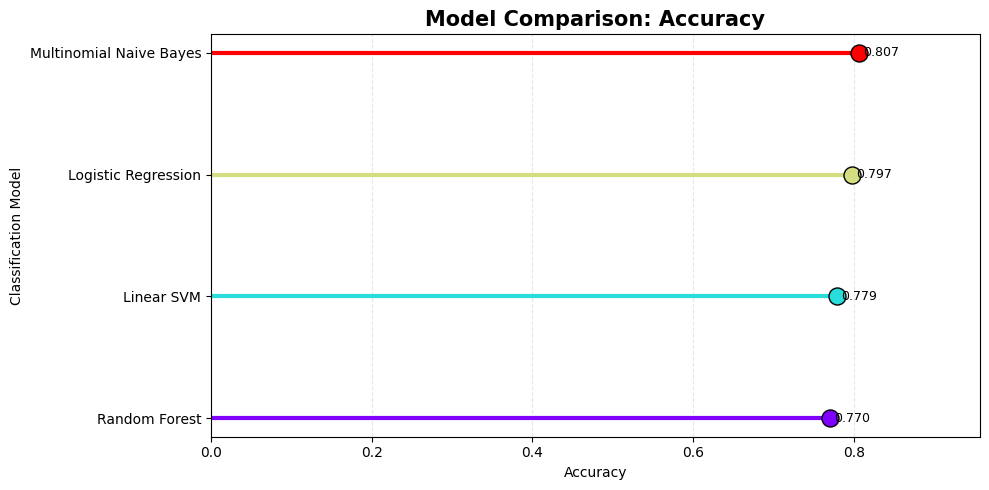

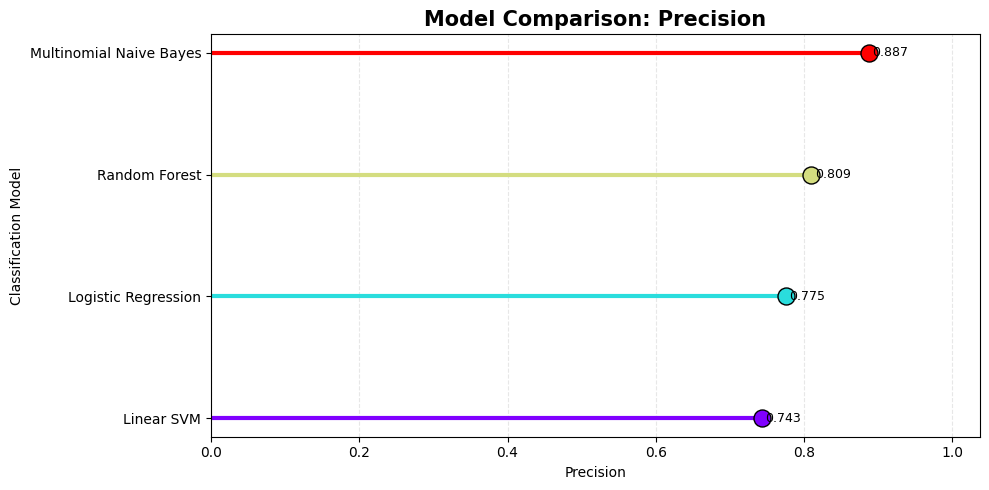

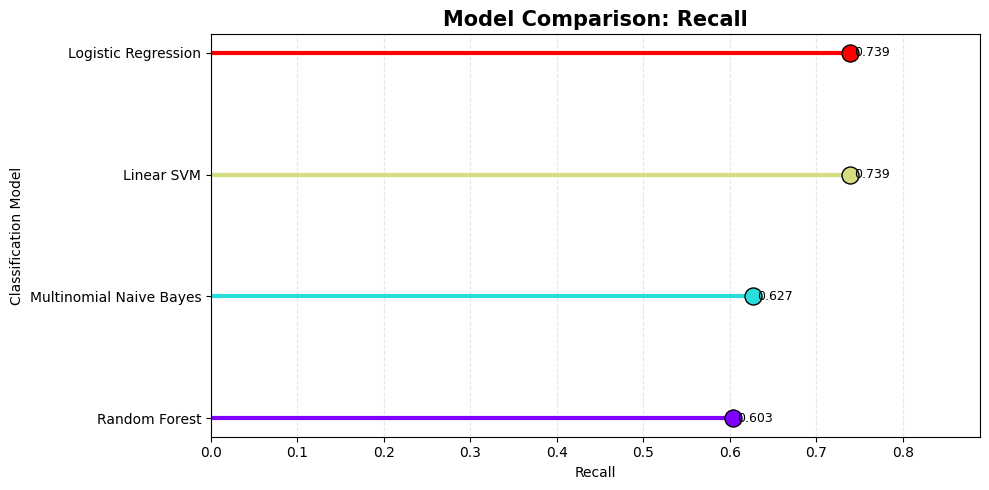

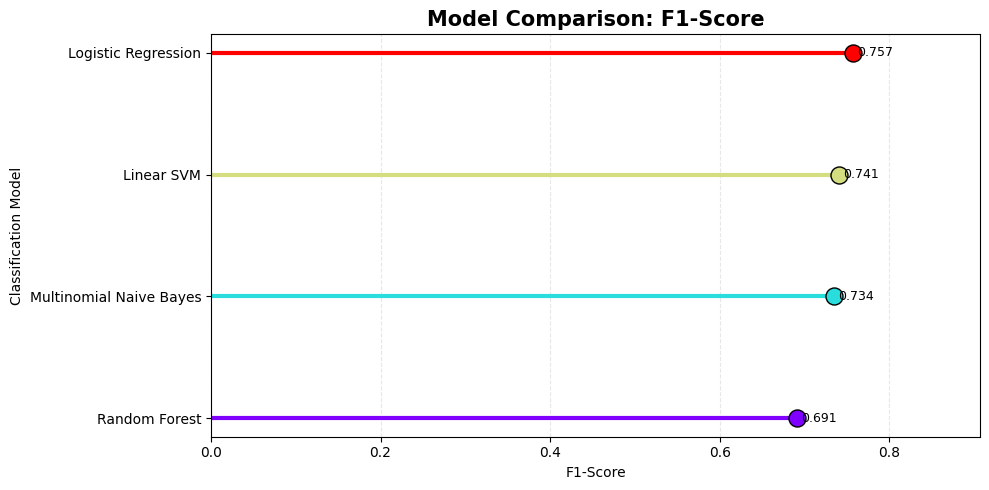

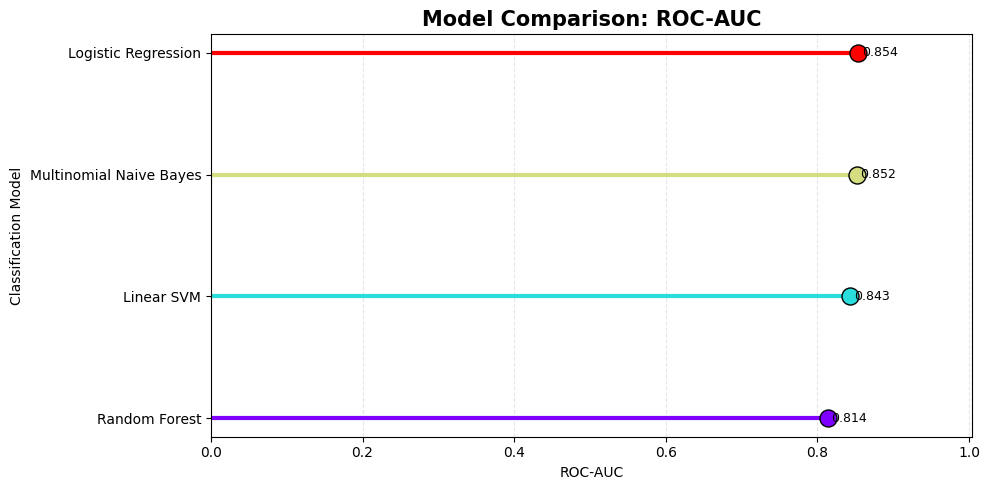

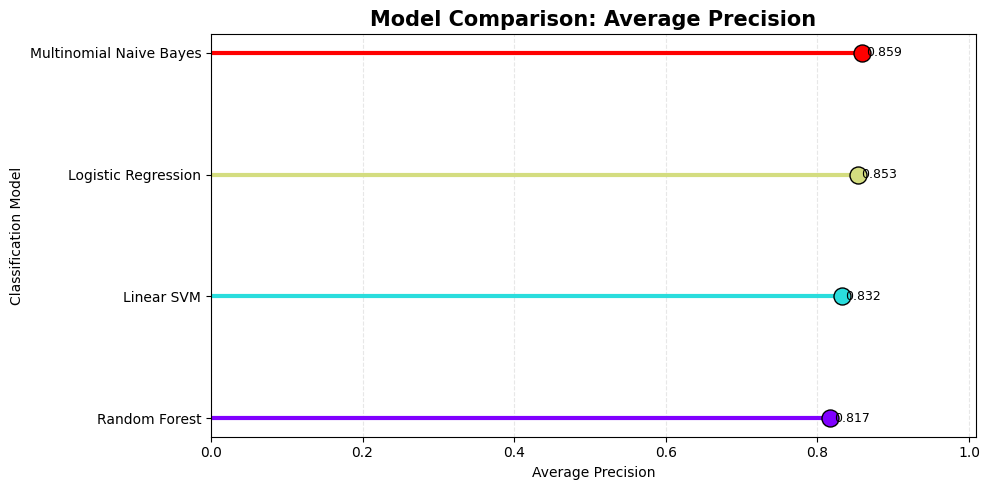

In [101]:
metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score",
    "ROC-AUC",
    "Average Precision"
]

for metric in metrics:

    plot_df = results_df.sort_values(
        by=metric,
        ascending=True
    ).reset_index(drop=True)

    colors = plt.cm.rainbow(
        np.linspace(0, 1, len(plot_df))
    )

    plt.figure(figsize=(10, 5))

    for i, row in plot_df.iterrows():

        plt.hlines(
            y=i,
            xmin=0,
            xmax=row[metric],
            color=colors[i],
            linewidth=3
        )

        plt.scatter(
            row[metric],
            i,
            color=colors[i],
            s=150,
            edgecolor="black",
            linewidth=1,
            zorder=3
        )

        plt.text(
            row[metric] + 0.005,
            i,
            f"{row[metric]:.3f}",
            va="center",
            fontsize=9
        )

    plt.yticks(
        range(len(plot_df)),
        plot_df["Model"]
    )

    plt.xlim(0, min(1.15, plot_df[metric].max() + 0.15))

    plt.title(
        f"Model Comparison: {metric}",
        fontsize=15,
        fontweight="bold"
    )

    plt.xlabel(metric)
    plt.ylabel("Classification Model")
    plt.grid(axis="x", linestyle="--", alpha=0.3)
    plt.tight_layout()
    plt.show()

These charts allow you to compare the models visually. The highest score is not automatically the best choice for every use case; consider the cost of missing disaster tweets and the number of false alarms.

## <span style="color:Lightpink"><b>Plot confusion matrices</b></span>

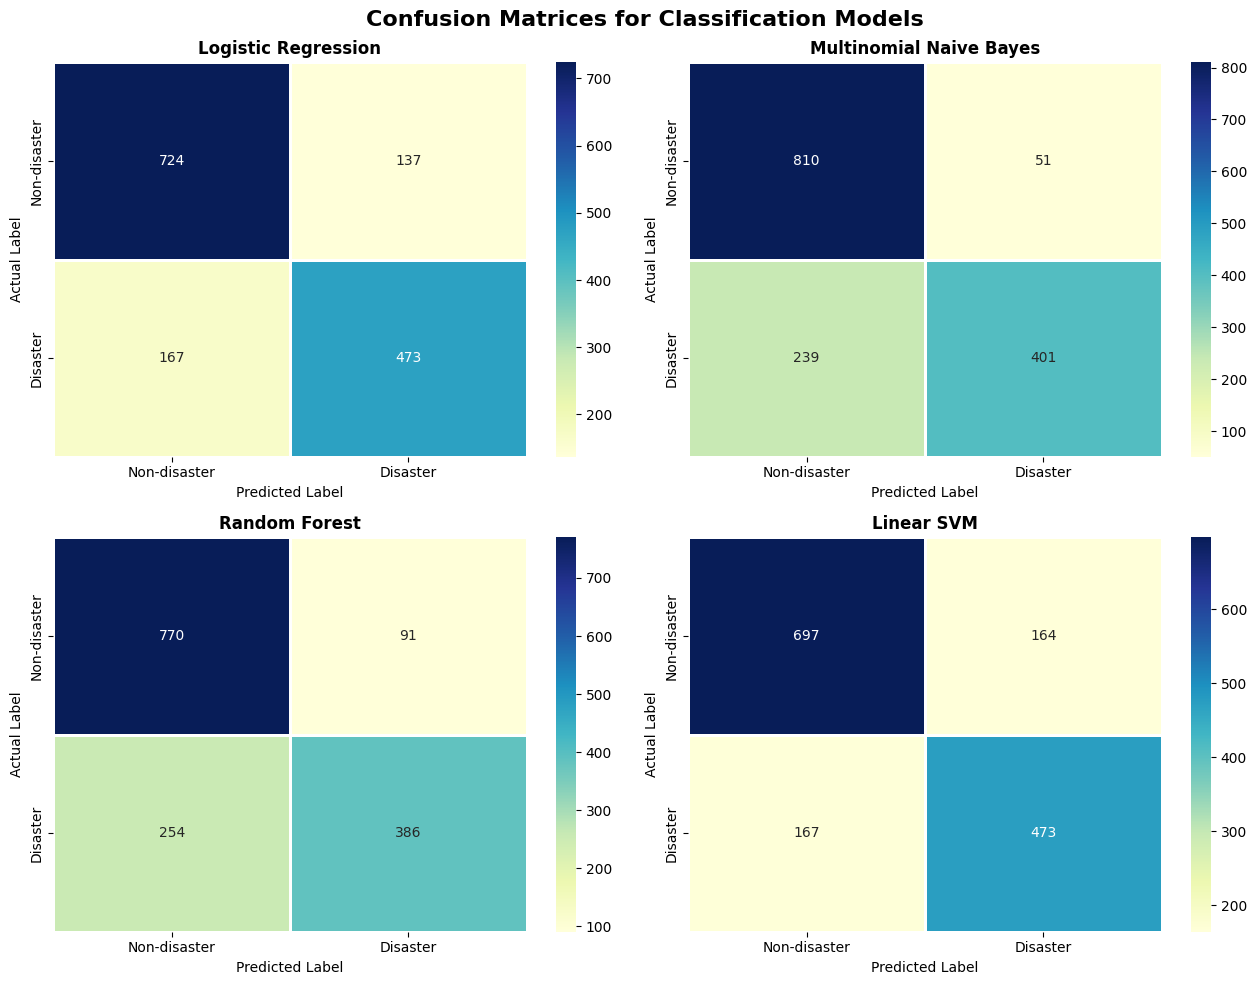

In [102]:
fig, axes = plt.subplots(
    2, 2,
    figsize=(13, 10)
)

axes = axes.flatten()

for i, (model_name, y_pred) in enumerate(predictions.items()):

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=[0, 1]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="YlGnBu",
        linewidths=1,
        xticklabels=["Non-disaster", "Disaster"],
        yticklabels=["Non-disaster", "Disaster"],
        ax=axes[i]
    )

    axes[i].set_title(
        model_name,
        fontsize=12,
        fontweight="bold"
    )

    axes[i].set_xlabel("Predicted Label")
    axes[i].set_ylabel("Actual Label")

plt.suptitle(
    "Confusion Matrices for Classification Models",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

How to interpret the confusion matrix
* True Negative (TN): A non-disaster tweet correctly predicted as non-disaster.
* True Positive (TP): A disaster tweet correctly predicted as disaster.
* False Positive (FP): A non-disaster tweet incorrectly predicted as disaster.
* False Negative (FN): A disaster tweet incorrectly predicted as non-disaster.

For disaster-related classification, a high number of false negatives may be undesirable.

## <span style="color:Lightpink"><b>Plot precision-recall curves</b></span>

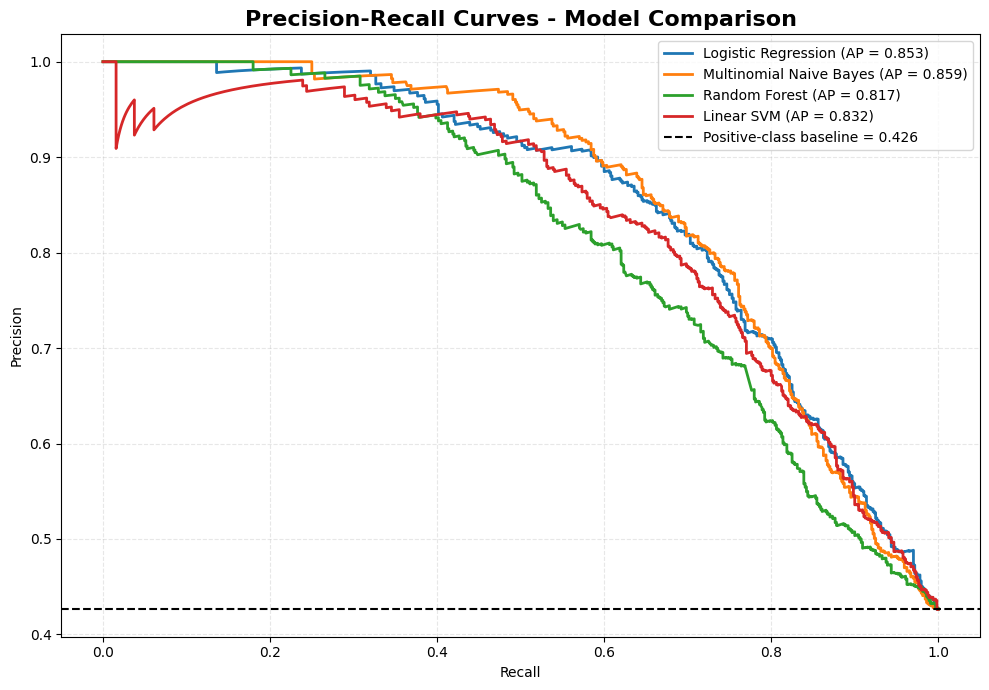

In [103]:
plt.figure(figsize=(10, 7))

for model_name, y_score in probability_scores.items():

    precision_values, recall_values, thresholds = (
        precision_recall_curve(y_test, y_score)
    )

    ap = average_precision_score(
        y_test,
        y_score
    )

    plt.plot(
        recall_values,
        precision_values,
        linewidth=2,
        label=f"{model_name} (AP = {ap:.3f})"
    )

# Baseline is the proportion of positive labels
baseline = y_test.mean()

plt.axhline(
    y=baseline,
    linestyle="--",
    color="black",
    label=f"Positive-class baseline = {baseline:.3f}"
)

plt.title(
    "Precision-Recall Curves - Model Comparison",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.legend(loc="best")
plt.grid(linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

Interpretation:

Higher precision means fewer false alarms among predicted disaster tweets.
Higher recall means more actual disaster tweets are identified.
A higher Average Precision score generally indicates better precision-recall performance.

The baseline is the positive-class prevalence in the test set.

## <span style="color:Lightpink"><b>Display the classification report</b></span>

In [104]:
for model_name, y_pred in predictions.items():

    print("\n" + "=" * 60)
    print(f"CLASSIFICATION REPORT: {model_name}")
    print("=" * 60)

    print(
        classification_report(
            y_test,
            y_pred,
            labels=[0, 1],
            target_names=["Non-disaster", "Disaster"],
            zero_division=0
        )
    )


CLASSIFICATION REPORT: Logistic Regression
              precision    recall  f1-score   support

Non-disaster       0.81      0.84      0.83       861
    Disaster       0.78      0.74      0.76       640

    accuracy                           0.80      1501
   macro avg       0.79      0.79      0.79      1501
weighted avg       0.80      0.80      0.80      1501


CLASSIFICATION REPORT: Multinomial Naive Bayes
              precision    recall  f1-score   support

Non-disaster       0.77      0.94      0.85       861
    Disaster       0.89      0.63      0.73       640

    accuracy                           0.81      1501
   macro avg       0.83      0.78      0.79      1501
weighted avg       0.82      0.81      0.80      1501


CLASSIFICATION REPORT: Random Forest
              precision    recall  f1-score   support

Non-disaster       0.75      0.89      0.82       861
    Disaster       0.81      0.60      0.69       640

    accuracy                           0.77      150

## <span style="color:Lightpink"><b>Select the best-performing model</b></span>

In [105]:
best_model_name = results_df.iloc[0]["Model"]

best_model = trained_models[best_model_name]

print("BEST MODEL")
print("=" * 40)
print("Model:", best_model_name)
print("Accuracy:", round(
    results_df.iloc[0]["Accuracy"], 4
))
print("Precision:", round(
    results_df.iloc[0]["Precision"], 4
))
print("Recall:", round(
    results_df.iloc[0]["Recall"], 4
))
print("F1-Score:", round(
    results_df.iloc[0]["F1-Score"], 4
))
print("ROC-AUC:", round(
    results_df.iloc[0]["ROC-AUC"], 4
))

BEST MODEL
Model: Logistic Regression
Accuracy: 0.7975
Precision: 0.7754
Recall: 0.7391
F1-Score: 0.7568
ROC-AUC: 0.8541


Important: This rule selects the highest F1-score from the test results. For a more rigorous final evaluation, choose the model using cross-validation on the training set, tune its hyperparameters there, and use the test set only once for final evaluation.

## <span style="color:Lightpink"><b>Save the selected model</b></span>

In [106]:
joblib.dump(
    best_model,
    "best_disaster_tweet_model.pkl"
)

print("Best model saved successfully!")
print("File: best_disaster_tweet_model.pkl")

Best model saved successfully!
File: best_disaster_tweet_model.pkl


In [107]:
loaded_model = joblib.load(
    "best_disaster_tweet_model.pkl"
)

new_tweets = [
    "Massive flooding has destroyed several houses",
    "I am having a wonderful day with my friends",
    "Emergency services are rescuing people after the earthquake"
]

new_predictions = loaded_model.predict(new_tweets)

for tweet, prediction in zip(new_tweets, new_predictions):

    label = (
        "Disaster-related"
        if prediction == 1
        else "Non-disaster"
    )

    print("Tweet:", tweet)
    print("Predicted class:", label)
    print("-" * 60)

Tweet: Massive flooding has destroyed several houses
Predicted class: Disaster-related
------------------------------------------------------------
Tweet: I am having a wonderful day with my friends
Predicted class: Non-disaster
------------------------------------------------------------
Tweet: Emergency services are rescuing people after the earthquake
Predicted class: Disaster-related
------------------------------------------------------------


## <span style="color:Lightpink"><b>Task 6: Model Validation</b></span>

## <span style="color:Lightpink"><b>Create the Selected Model</b></span>

For this example, we will use Logistic Regression with TF-IDF. It is a useful baseline for text classification.


In [111]:
# Create the TF-IDF and Logistic Regression pipeline
model = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            max_features=10000,
            ngram_range=(1, 2),
            min_df=2,
            sublinear_tf=True
        )
    ),
    (
        "classifier",
        LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=42
        )
    )
])

# Train using only the training dataset
model.fit(X_train, y_train)

print("Selected model trained successfully!")

Selected model trained successfully!


## <span style="color:Lightpink"><b>Validate the Model on Training and Testing Data</b></span>


In [112]:
# Predictions on training and testing datasets
train_predictions = model.predict(X_train)
test_predictions = model.predict(X_test)

# Calculate performance metrics
results = pd.DataFrame({
    "Dataset": ["Training", "Testing"],
    "Accuracy": [
        accuracy_score(y_train, train_predictions),
        accuracy_score(y_test, test_predictions)
    ],
    "Precision": [
        precision_score(y_train, train_predictions, zero_division=0),
        precision_score(y_test, test_predictions, zero_division=0)
    ],
    "Recall": [
        recall_score(y_train, train_predictions, zero_division=0),
        recall_score(y_test, test_predictions, zero_division=0)
    ],
    "F1-Score": [
        f1_score(y_train, train_predictions, zero_division=0),
        f1_score(y_test, test_predictions, zero_division=0)
    ]
})

print("Training vs Testing Performance")
display(results.round(4))

Training vs Testing Performance


,Dataset,Accuracy,Precision,Recall,F1-Score
0,Training,0.8904,0.8913,0.8460,0.8680
1,Testing,0.7975,0.7754,0.7391,0.7568


## <span style="color:Lightpink"><b>Visualize Overfitting and Underfitting</b></span>
This chart compares training and testing performance using different colors for each metric.

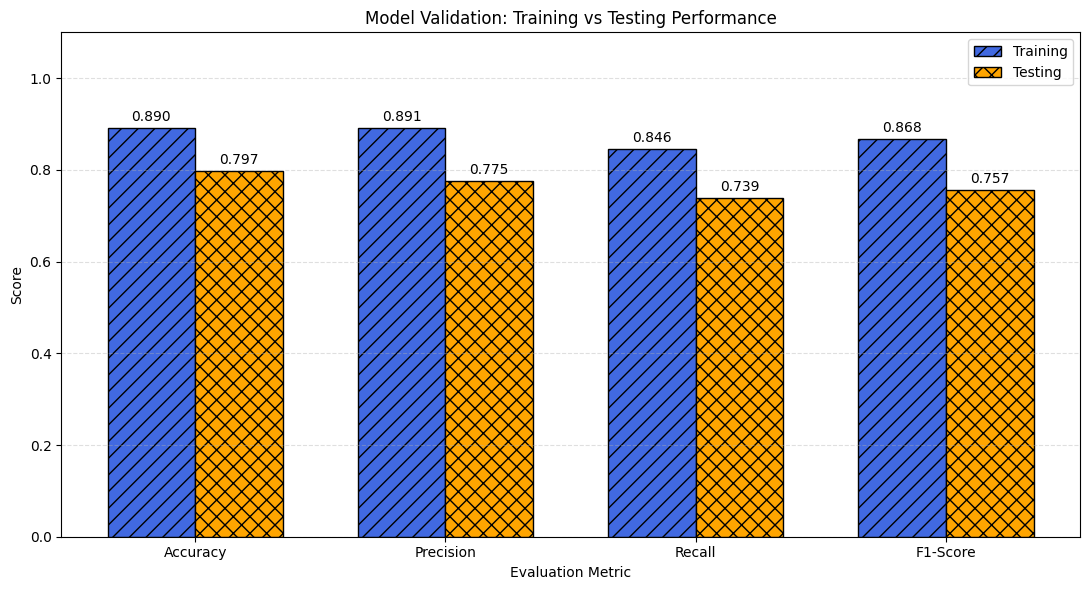

In [113]:
metrics = ["Accuracy", "Precision", "Recall", "F1-Score"]

x = np.arange(len(metrics))
width = 0.35

fig, ax = plt.subplots(figsize=(11, 6))

train_values = results.iloc[0][metrics].values.astype(float)
test_values = results.iloc[1][metrics].values.astype(float)

bars1 = ax.bar(
    x - width / 2,
    train_values,
    width,
    label="Training",
    color="royalblue",
    edgecolor="black",
    hatch="//"
)

bars2 = ax.bar(
    x + width / 2,
    test_values,
    width,
    label="Testing",
    color="orange",
    edgecolor="black",
    hatch="xx"
)

ax.set_title("Model Validation: Training vs Testing Performance")
ax.set_ylabel("Score")
ax.set_xlabel("Evaluation Metric")
ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.set_ylim(0, 1.1)
ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.4)

ax.bar_label(bars1, fmt="%.3f", padding=3)
ax.bar_label(bars2, fmt="%.3f", padding=3)

plt.tight_layout()
plt.show()

### What this graph tells you: 
If the training bars are substantially higher than the testing bars, investigate possible overfitting. If both sets of scores are low, investigate possible underfitting or weak features.

## <span style="color:Lightpink"><b>Check Cross-Validation Performance</b></span>
Cross-validation evaluates the model on multiple splits of the training data. This helps you determine whether performance is consistent across different subsets.

The test dataset is not used in this step.

In [124]:
from sklearn.model_selection import cross_val_score, StratifiedKFold

print("cross_val_score imported successfully!")

cross_val_score imported successfully!


In [125]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_scores = cross_val_score(
    model,
    X_train,
    y_train,
    cv=cv,
    scoring="f1",
    n_jobs=-1
)

print("Cross-Validation F1 Scores:")
for i, score in enumerate(cv_scores, start=1):
    print(f"Fold {i}: {score:.4f}")

print("\nMean CV F1-Score:", round(cv_scores.mean(), 4))
print("Standard Deviation:", round(cv_scores.std(), 4))

Cross-Validation F1 Scores:
Fold 1: 0.7659
Fold 2: 0.7462
Fold 3: 0.7445
Fold 4: 0.7548
Fold 5: 0.7425

Mean CV F1-Score: 0.7508
Standard Deviation: 0.0086


### Interpretation
A high mean F1-score suggests good average performance.
A small standard deviation suggests more consistent performance across folds.
A large standard deviation suggests performance varies across the training subsets.

Cross-validation is more informative than relying on one training/testing split alone.


## <span style="color:Lightpink"><b>Test Robustness to Tweet Text Variations</b></span>
Real tweets can contain uppercase letters, URLs, mentions, and different punctuation. The following test checks whether your model produces predictions for varied versions of similar text.


In [117]:
# Tweets expressing similar meanings in different formats
test_tweets = [
    "Flooding has destroyed several homes in the area",
    "FLOODING HAS DESTROYED SEVERAL HOMES IN THE AREA!!!",
    "Flooding has destroyed several homes in the area https://example.com",
    "@user Flooding has destroyed several homes in the area",
    "There is flooding and many homes are damaged",
    "I love watching the rain from my window",
    "The weather is beautiful today"
]

# Apply the same cleaning function used during training
cleaned_tweets = [clean_text(tweet) for tweet in test_tweets]

# Predict class labels
predictions = model.predict(cleaned_tweets)

# Get prediction confidence where available
if hasattr(model, "predict_proba"):
    probabilities = model.predict_proba(cleaned_tweets)
    confidence = probabilities.max(axis=1)
else:
    confidence = [np.nan] * len(test_tweets)

# Display results
robustness_results = pd.DataFrame({
    "Original Tweet": test_tweets,
    "Cleaned Tweet": cleaned_tweets,
    "Prediction": [
        "Disaster" if prediction == 1 else "Non-Disaster"
        for prediction in predictions
    ],
    "Model Confidence": confidence
})

display(robustness_results.round(3))

,Original Tweet,Cleaned Tweet,Prediction,Model Confidence
0,Flooding has destroyed several homes in the area,flooding has destroyed several homes in the area,Disaster,0.788
1,FLOODING HAS DESTROYED SEVERAL HOMES IN THE AR...,flooding has destroyed several homes in the area,Disaster,0.788
2,Flooding has destroyed several homes in the ar...,flooding has destroyed several homes in the area,Disaster,0.788
3,@user Flooding has destroyed several homes in ...,flooding has destroyed several homes in the area,Disaster,0.788
4,There is flooding and many homes are damaged,there is flooding and many homes are damaged,Disaster,0.607
5,I love watching the rain from my window,i love watching the rain from my window,Non-Disaster,0.636
6,The weather is beautiful today,the weather is beautiful today,Disaster,0.546


### How to interpret this test: 
Compare predictions for tweets with similar wording. If capitalization, URLs, or mentions change the prediction unexpectedly, inspect the preprocessing and model behavior.

This is a small diagnostic test, not proof of overall robustness. The model's confidence is not necessarily a calibrated probability of correctness.

## <span style="color:Lightpink"><b>Plot Model Confidence for the Test Tweets</b></span>

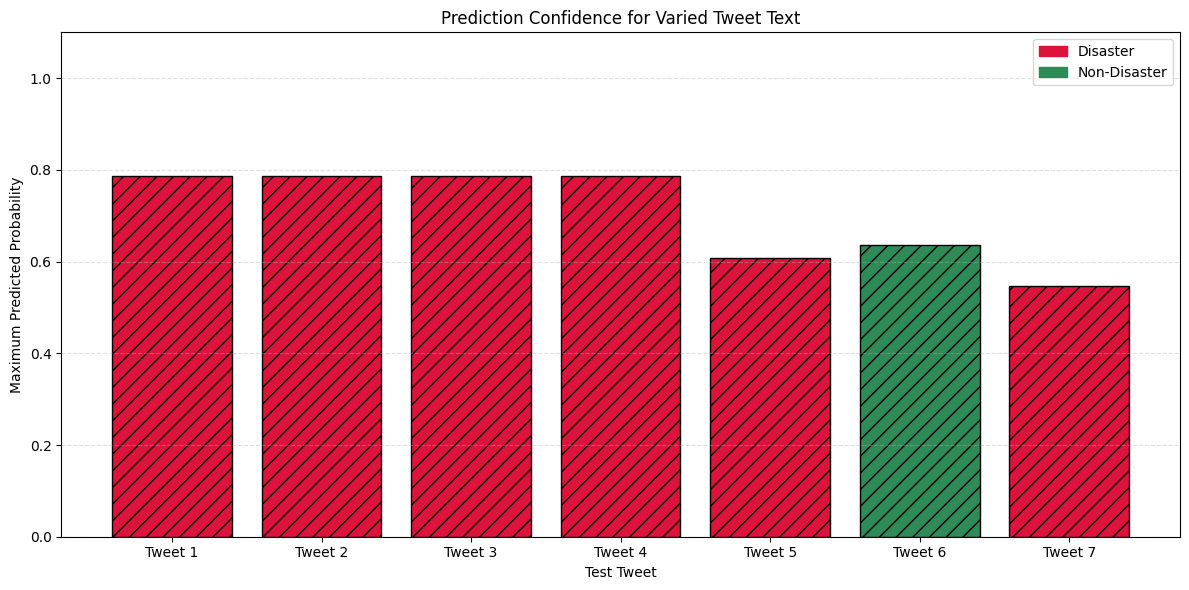

In [118]:
if hasattr(model, "predict_proba"):
    plt.figure(figsize=(12, 6))

    colors = [
        "crimson" if prediction == 1 else "seagreen"
        for prediction in predictions
    ]

    bars = plt.bar(
        range(len(test_tweets)),
        confidence,
        color=colors,
        edgecolor="black",
        hatch="//"
    )

    plt.xticks(
        range(len(test_tweets)),
        [f"Tweet {i+1}" for i in range(len(test_tweets))]
    )

    plt.ylabel("Maximum Predicted Probability")
    plt.xlabel("Test Tweet")
    plt.title("Prediction Confidence for Varied Tweet Text")
    plt.ylim(0, 1.1)
    plt.grid(axis="y", linestyle="--", alpha=0.4)

    plt.legend(
        handles=[
            plt.Rectangle((0, 0), 1, 1, color="crimson", label="Disaster"),
            plt.Rectangle((0, 0), 1, 1, color="seagreen", label="Non-Disaster")
        ]
    )

    plt.tight_layout()
    plt.show()
else:
    print("Probability estimates are unavailable for this model.")

This chart shows how confident the model is in its predictions, not whether the predictions are necessarily correct. The example tweets should be manually checked because their actual labels are not provided.

## <span style="color:Lightpink"><b>Adjust the Model if Overfitting Is Suspected</b></span>
If the training score is substantially higher than the testing score, try stronger regularization by reducing C in Logistic Regression.

A smaller C applies stronger regularization and can help reduce overfitting.

In [126]:
# Try different regularization strengths
C_values = [0.01, 0.1, 1.0, 10.0]

tuning_results = []

for C_value in C_values:

    candidate_model = Pipeline([
        (
            "tfidf",
            TfidfVectorizer(
                max_features=10000,
                ngram_range=(1, 2),
                min_df=2,
                sublinear_tf=True
            )
        ),
        (
            "classifier",
            LogisticRegression(
                C=C_value,
                max_iter=1000,
                class_weight="balanced",
                random_state=42
            )
        )
    ])

    scores = cross_val_score(
        candidate_model,
        X_train,
        y_train,
        cv=cv,
        scoring="f1",
        n_jobs=-1
    )

    tuning_results.append({
        "C": C_value,
        "Mean CV F1": scores.mean(),
        "CV F1 Std": scores.std()
    })

tuning_df = pd.DataFrame(tuning_results)

display(tuning_df.round(4))

,C,Mean CV F1,CV F1 Std
0,0.01,0.7245,0.0086
1,0.10,0.7333,0.0128
2,1.00,0.7508,0.0086
3,10.00,0.7395,0.0114


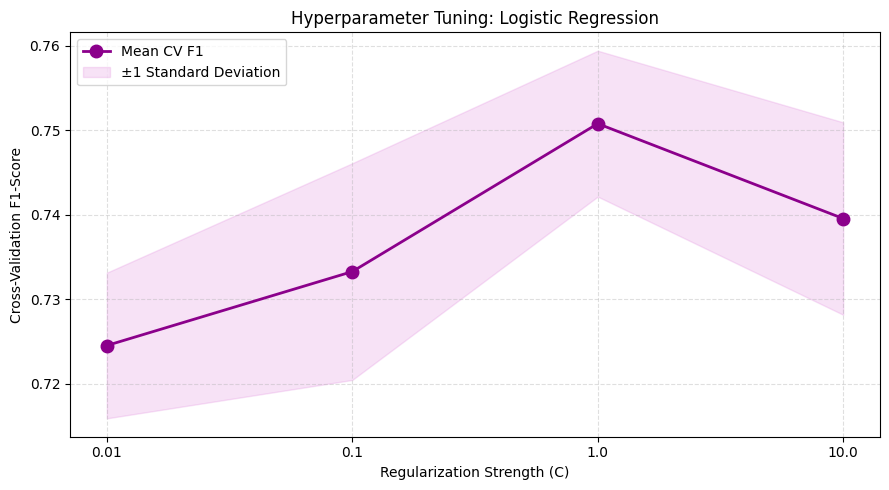

In [127]:
plt.figure(figsize=(9, 5))

plt.plot(
    tuning_df["C"].astype(str),
    tuning_df["Mean CV F1"],
    marker="o",
    markersize=9,
    linewidth=2,
    color="darkmagenta",
    label="Mean CV F1"
)

plt.fill_between(
    range(len(tuning_df)),
    tuning_df["Mean CV F1"] - tuning_df["CV F1 Std"],
    tuning_df["Mean CV F1"] + tuning_df["CV F1 Std"],
    alpha=0.2,
    color="orchid",
    label="±1 Standard Deviation"
)

plt.title("Hyperparameter Tuning: Logistic Regression")
plt.xlabel("Regularization Strength (C)")
plt.ylabel("Cross-Validation F1-Score")
plt.xticks(range(len(tuning_df)), tuning_df["C"].astype(str))
plt.grid(linestyle="--", alpha=0.4)
plt.legend()
plt.tight_layout()
plt.show()

Choose the C value with the best mean cross-validation F1-score. If scores are very similar, consider the simpler, more strongly regularized model.

## <span style="color:Lightpink"><b>Train the Final Model and Evaluate It Once</b></span>
After choosing the hyperparameter using cross-validation, fit the final model on the training data and evaluate it on the held-out test data.

In [128]:
# Select best C based on cross-validation
best_C = tuning_df.loc[
    tuning_df["Mean CV F1"].idxmax(),
    "C"
]

print("Selected C:", best_C)

# Create final pipeline
final_model = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            max_features=10000,
            ngram_range=(1, 2),
            min_df=2,
            sublinear_tf=True
        )
    ),
    (
        "classifier",
        LogisticRegression(
            C=best_C,
            max_iter=1000,
            class_weight="balanced",
            random_state=42
        )
    )
])

# Fit on training data only
final_model.fit(X_train, y_train)

# Evaluate on held-out test data
final_predictions = final_model.predict(X_test)

print("Final Test Accuracy:",
      round(accuracy_score(y_test, final_predictions), 4))

print("Final Test Precision:",
      round(precision_score(y_test, final_predictions, zero_division=0), 4))

print("Final Test Recall:",
      round(recall_score(y_test, final_predictions, zero_division=0), 4))

print("Final Test F1-Score:",
      round(f1_score(y_test, final_predictions, zero_division=0), 4))

Selected C: 1.0
Final Test Accuracy: 0.7975
Final Test Precision: 0.7754
Final Test Recall: 0.7391
Final Test F1-Score: 0.7568


Do not keep adjusting the model based on the test score. If you do, the test dataset gradually becomes part of the model-selection process. Use cross-validation for tuning and reserve the test set for final evaluation.

## <span style="color:Lightpink"><b>Save the Validated Model</b></span>

In [129]:
joblib.dump(final_model, "validated_disaster_tweet_model.pkl")

print("Validated model saved successfully!")

Validated model saved successfully!


In [130]:
loaded_model = joblib.load("validated_disaster_tweet_model.pkl")

new_tweet = "Heavy flooding has affected several villages"

cleaned_tweet = clean_text(new_tweet)

prediction = loaded_model.predict([cleaned_tweet])[0]

if prediction == 1:
    print("Prediction: Disaster-related tweet")
else:
    print("Prediction: Non-disaster tweet")

Prediction: Disaster-related tweet


Final Report: Model Validation

### Objective:
 To evaluate the selected Twitter disaster classification model on unseen data, identify possible overfitting or underfitting, and assess its robustness to variations in tweet text.

### Methodology:

* Split the dataset into training and testing subsets, using stratification to preserve the class distribution.
* Train the selected Logistic Regression model using TF-IDF text features.
* Compare training and testing accuracy, precision, recall, and F1-score.
* Apply five-fold stratified cross-validation to assess consistency across training subsets.
* Analyze the confusion matrix and classification report to identify classification errors.
* Test predictions on tweets containing variations in capitalization, punctuation, URLs, and mentions.
* Tune Logistic Regression's regularization strength using cross-validation if necessary.
* Save the final validated model for future predictions.

### Conclusion: 
The model's generalization ability should be assessed by comparing training and testing performance, reviewing cross-validation variability, and examining errors on unseen tweets. Robustness tests can reveal sensitivity to text variations, but further testing on a larger, independently labeled dataset is needed before drawing strong conclusions about real-world reliability.

### Important:
 Run the notebook cells and insert your actual accuracy, precision, recall, F1-score, and cross-validation results into your report. Do not claim that the model is robust or free from overfitting until the results support that conclusion.

 ## <span style="color:green"><b>Part 4: Deployment with Web Interface</b></span>

## <span style="color:LIGHTpink"><b> Task 7: Model Deployment</b></span>
The trained disaster tweet classification model was serialized using Python's Pickle library. The TF-IDF vectorizer was also saved so that new tweets can be transformed using the same feature representation used during model training.

Web Application:
A Flask-based web application was developed to provide an interactive interface for users. The application loads the trained model and TF-IDF vectorizer when the server starts.

Prediction:
Users can enter or paste tweet content into the web interface. The tweet is cleaned using the same preprocessing steps used during training and transformed using TF-IDF. The trained classification model then predicts whether the tweet is disaster-related or non-disaster-related.

User Interface:
The interface provides a text box for entering tweets, a classification button, the predicted class, and the model confidence score. Instructions are also provided to help users understand how to use the application.

Deployment:
The Flask application can first be tested locally using 127.0.0.1:5000 and can subsequently be deployed to a cloud hosting service.


In [131]:
import joblib

joblib.dump(
    final_model,
    "validated_disaster_tweet_model.pkl"
)

print("Model saved successfully!")

Model saved successfully!


In [132]:
import os

print(os.path.exists("validated_disaster_tweet_model.pkl"))

True


In [133]:
import sklearn

print(sklearn.__version__)

1.9.0


## <span style="color:LIGHTpink"><b> Task 8: User Interface Design</b></span>

                 USER
                   │
                   ▼
        ┌─────────────────────┐
        │   Flask Web Page    │
        │  Enter Tweet Text   │
        └──────────┬──────────┘
                   │
                   ▼
        ┌─────────────────────┐
        │    Text Cleaning    │
        │ URLs / symbols etc.│
        └──────────┬──────────┘
                   │
                   ▼
        ┌─────────────────────┐
        │    TF-IDF Vectorizer│
        └──────────┬──────────┘
                   │
                   ▼
        ┌─────────────────────┐
        │ Logistic Regression │
        │       Model         │
        └──────────┬──────────┘
                   │
                   ▼
          ┌─────────────────┐
          │   Prediction    │
          │                 │
          │ Disaster /      │
          │ Non-Disaster    │
          └─────────────────┘

## Conclusion

By successfully developing and deploying a machine learning model to classify disaster-related tweets, this project demonstrates how Natural Language Processing (NLP) can help identify potentially important information during emergencies. The model classifies tweets as disaster-related or non-disaster-related, supporting faster analysis of social media content.

The integration of the trained model into a Flask web application provides a simple, user-friendly interface for making predictions. This project highlights the potential of machine learning to improve disaster information monitoring, support emergency response teams, and contribute to public safety efforts. Although the model may occasionally misclassify tweets, further improvements in training data, model performance, and real-time analysis could increase its usefulness in practical disaster management applications.


In [5]:
print("*" * 50)
print("NLP Project for Disaster Tweet Classification!")
print("*" * 50)

print('\n📌 Project Name : NLP Project for Disaster Tweet Classification!')
print("👤 Submitted By : Iram Shafi")
print("📅 Date         : 15-October-2026")

print("*" * 50)


**************************************************
NLP Project for Disaster Tweet Classification!
**************************************************

📌 Project Name : NLP Project for Disaster Tweet Classification!
👤 Submitted By : Iram Shafi
📅 Date         : 15-October-2026
**************************************************
